In [1]:
import matplotlib.pyplot as plot
import pandas
import seaborn
import re
import numpy as np
from scipy import stats

seaborn.set_theme(style='ticks', context='paper', palette='plasma')

LEADS_PATH, PEDIDOS_PATH = '../data/churn_aplicacao_leads_final.csv', '../data/churn_comportamental_pedidos_final.csv'

In [2]:
leads = pandas.read_csv(LEADS_PATH)
pedidos = pandas.read_csv(PEDIDOS_PATH)

In [3]:
leads.churned.value_counts()

churned
0    1096
1     904
Name: count, dtype: int64

In [4]:
leads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       2000 non-null   int64  
 1   uf                               2000 non-null   object 
 2   municipio                        2000 non-null   object 
 3   segmento_cliente                 2000 non-null   object 
 4   natureza_juridica                2000 non-null   object 
 5   fonte_cliente                    2000 non-null   object 
 6   cnae_codigo                      2000 non-null   object 
 7   capital_social                   2000 non-null   object 
 8   idade_cnpj                       2000 non-null   object 
 9   serasa_contagem_negativacoes     2000 non-null   float64
 10  serasa_contagem_protestos        2000 non-null   float64
 11  serasa_credores                  190 non-null    object 
 12  serasa_socio_tem_neg

In [5]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4441 entries, 0 to 4440
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id_pedido     4441 non-null   int64 
 1   id_cliente    4441 non-null   int64 
 2   valor         4438 non-null   object
 3   produtos      4440 non-null   object
 4   data_entrega  4441 non-null   object
dtypes: int64(2), object(3)
memory usage: 173.6+ KB


Cruzando a tabela de leads com a de pedidos:

In [6]:
joined = leads.merge(right=pedidos, on='id_cliente', how='left')

Análise estrutural dos dados:

In [7]:
joined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5441 entries, 0 to 5440
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       5441 non-null   int64  
 1   uf                               5441 non-null   object 
 2   municipio                        5441 non-null   object 
 3   segmento_cliente                 5441 non-null   object 
 4   natureza_juridica                5441 non-null   object 
 5   fonte_cliente                    5441 non-null   object 
 6   cnae_codigo                      5441 non-null   object 
 7   capital_social                   5441 non-null   object 
 8   idade_cnpj                       5441 non-null   object 
 9   serasa_contagem_negativacoes     5441 non-null   float64
 10  serasa_contagem_protestos        5441 non-null   float64
 11  serasa_credores                  447 non-null    object 
 12  serasa_socio_tem_neg

Porcentagem de faltantes por coluna:

In [8]:
print('faltantes por atributo em LEADS')
for label in leads.columns:
    column: pandas.Series = leads[label]
    missing_pct = 100 * column.isna().sum() / column.size
    
    if missing_pct > 0:
        print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

faltantes por atributo em LEADS
serasa_credores                  | 90.50% (1810/2000)
ifood_contagem_avaliacoes        | 94.30% (1886/2000)
ifood_faixa_preco                | 87.85% (1757/2000)
google_maps_avaliacao            | 97.80% (1956/2000)
google_maps_contagem_avaliacoes  | 91.25% (1825/2000)
google_maps_tem_website          | 91.25% (1825/2000)


- Muitos faltantes
- `google_maps_tem_website` é só uma flag booleana
- Se você não tiver website no google maps, você não vai ter avaliações
- Se você não tiver ifood, não terá faixa de preço nem avaliações
- Tudo bem não ter credores no serasa

In [9]:
print('faltantes por atributo em PEDIDOS')
for label in pedidos.columns:
    column: pandas.Series = pedidos[label]
    missing_pct = 100 * column.isna().sum() / column.size
        
    if missing_pct > 0:
        print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

faltantes por atributo em PEDIDOS
valor                            | 0.07% (3/4441)
produtos                         | 0.02% (1/4441)


Quantidade de ocorrências de cada cliente na tabela de pedidos:

In [10]:
pedidos.id_cliente.value_counts()

id_cliente
1739936841220    56
8113331192324    46
7243866379881    44
1560063946241    29
1222295907587    29
                 ..
6388676592025     1
1972150366050     1
2150548890639     1
5283377970744     1
1834318012896     1
Name: count, Length: 1000, dtype: int64

IDs dos clientes cujos pedidos tem `valor` ou `produtos`  nulos:

In [11]:
pedidos[pedidos.valor.isna() | pedidos.produtos.isna()]

,id_pedido,id_cliente,valor,produtos,data_entrega
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10


- Temos que achar uma maneira de imputar esses valores com base nos outros pedidos desses clientes

Contando valores únicos para cada atributo:

In [12]:
for label in joined.columns:
    column: pandas.Series = joined[label]

    # Contando os valores únicos:
    unique_values = column.unique()
    print(f'{label:32s} | {unique_values.size!s:5s}', end='')

    # Imprimindo os valores possíveis para
    # os atributos somente se são poucos:
    if unique_values.size <= 20:
        values_str = ', '.join(str(v) for v in unique_values)
        print(f'({values_str})', end='')

    print()

id_cliente                       | 2000 
uf                               | 1    (CE)
municipio                        | 31   
segmento_cliente                 | 21   
natureza_juridica                | 4    (206-2 - Sociedade Empresária Limitada, 213-5 - Empresário (Individual), 230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária), 224-0 - Sociedade Simples Limitada)
fonte_cliente                    | 5    (Fonte 5, Fonte 1, Fonte 3, Fonte 2, Fonte 4)
cnae_codigo                      | 107  
capital_social                   | 19   ((70000, 100000], (3000, 5000], (8000, 10000], (200000, 1000000], (15000, 20000], (50000, 70000], (30000, 50000], (5000, 8000], (100000, 200000], (20000, 30000], (1000000, 10000000], (10000, 15000], (0, 1], (1500, 2000], (200, 1000], (1, 200], (1000, 1500], (2000, 3000], (10000000, 100000000000])
idade_cnpj                       | 20   ((8000, 25000], (5000, 8000], (1300, 1600], (2000, 2400], (50, 100], (2400, 3000], (4000, 5000],

- Só tem um estado (CE)
- `google_maps_tem_website` tem valores (1.0, nan).
- `google_maps_avaliacao` não tem valor no intervalo `(4.0, 4.5]`
- `capital_social`, `idade_cnpj`, `ifood_contagem_avaliacoes`, `valor` (pedido) e `produtos` (pedido) são dados em 

In [13]:
#Hierarquia do CNAE no estilo do dataset:
# AA -> divisão
# AA.B -> grupo
# AA.BC-C -> classe
# AA.BC-C-DD -> subclasse

# Contando divisões únicas
divisoes = {cnae[:2] for cnae in leads.cnae_codigo}

print(f'quantidade de divisões CNAE: {len(divisoes)} | {sorted(divisoes)}')
print(f'exemplos de alguns códigos: {sorted(leads.cnae_codigo)[:5]}')

quantidade de divisões CNAE: 27 | ['12', '14', '20', '23', '24', '25', '29', '30', '33', '36', '37', '38', '39', '52', '53', '64', '70', '74', '76', '77', '78', '81', '83', '85', '93', '96', '97']
exemplos de alguns códigos: ['12.10-3-97', '12.74-7-12', '12.74-7-32', '12.74-7-79', '14.17-3-90']


- Segundo detalhamento da IBGE/CONCLA dos [códigos CNAE 2.3](https://cnae.ibge.gov.br/images/concla/documentacao/CNAE_Subclasses_2_3_Estrutura_Detalhada.xlsx), não existe o código `12.10-3/97` por exemplo
- Não podemos contar que esses valores tenham significado explícito 
- O Notion dizia que podemos contar com a hierarquia dos códigos, mas o que isso significa?

In [14]:
print(f'quantidade de valores únicos para credores serasa: {leads.serasa_credores.nunique()}')
print(f'lista de credores: {sorted(leads.serasa_credores.dropna().unique())}')

quantidade de valores únicos para credores serasa: 49
lista de credores: ['Alimentos e Bebidas', 'Alimentos e Bebidas, Alimentos e Bebidas, Alimentos e Bebidas', 'Alimentos e Bebidas, Bancos e Financeiro', 'Alimentos e Bebidas, Bancos e Financeiro, Alimentos e Bebidas', 'Alimentos e Bebidas, Bancos e Financeiro, Bancos e Financeiro, Financeiro, Alimentos e Bebidas, Alimentos e Bebidas, Indústria', 'Alimentos e Bebidas, Saúde', 'Alimentos e Bebidas, Tecnologia e Pagamentos', 'Bancos e Financeiro', 'Bancos e Financeiro, Alimentos e Bebidas, Bancos e Financeiro', 'Bancos e Financeiro, Alimentos e Bebidas, Distribuição', 'Bancos e Financeiro, Bancos e Financeiro', 'Bancos e Financeiro, Bancos e Financeiro, Bancos e Financeiro', 'Bancos e Financeiro, Bancos e Financeiro, Telecomunicações, Contabilidade', 'Bancos e Financeiro, Comunicação', 'Bancos e Financeiro, Financeiro', 'Bancos e Financeiro, Tecnologia e Pagamentos', 'Bancos e Financeiro, Tecnologia e Pagamentos, Bancos e Financeiro', '

- Não existem 49 valores diferentes de fato, são uma lista de valores separados por vírgulas
- Existem listas com valores repetidos, pq?
- É preciso olhar valor por valor para decidir como separar os valores únicos de cada lista de fato:

> Serasa_credores: Até 5 empresas diferentes para as quais o cliente deve. Se o cliente dever para mais de 5 empresas diferentes, as 5 mais recentes serão exibidas. Os dados estão anonimizados, identificando apenas o segmento de cada um dos credores (ex. Comércio). No caso do cliente não dever para outra empresa, o campo é nulo.

In [15]:
credores: set[str] = set()

for credor in leads.serasa_credores.dropna().unique():
    credores.update(credor.split(', '))

print(f'{len(credores)} categorias únicas de credores:')
sorted(credores)

21 categorias únicas de credores:


['Alimentos e Bebidas',
 'Bancos e Financeiro',
 'Comunicação',
 'Comércio',
 'Contabilidade',
 'Distribuição',
 'Diversos',
 'Energia',
 'Financeiro',
 'Imobiliário',
 'Indústria',
 'Logística',
 'Saúde',
 'Seguros e Financeiro',
 'Serviços',
 'Serviços Ambientais',
 'Tecnologia',
 'Tecnologia e Pagamentos',
 'Telecomunicações',
 'Varejo',
 'Viagens e Turismo']

só verificando se esses são categóricos ou não msm

In [16]:
leads.serasa_contagem_negativacoes.unique()

array([  0.,  14.,   6.,   2.,   1.,   3.,   4.,  10.,  15.,  16.,  19.,
         7.,   5.,  11.,  22.,  52.,   8.,   9., 223.,  12.,  25.,  29.,
        30.,  33.,  21., 162.,  99.])

In [17]:
leads.segmento_cliente.unique()

array(['Segmento 5', 'Segmento 19', 'Segmento 20', 'Segmento 13',
       'Segmento 18', 'Segmento 14', 'Segmento 3', 'Segmento 10',
       'Segmento 15', 'Segmento 4', 'Segmento 16', 'Segmento 8',
       'Segmento 6', 'Segmento 9', 'Segmento 17', 'Segmento 2',
       'Segmento 21', 'Segmento 7', 'Segmento 1', 'Segmento 11',
       'Segmento 12'], dtype=object)

In [18]:
datas = pedidos.data_entrega
# pegando o período das datas de entregas
meses: set[str] = {date[:7] for date in datas.dropna().unique()}

print(f'meses: {sorted(meses)}')
print(f'quantidade de pedidos sem data de entrega: {datas.isna().sum()}')

meses: ['2024-09', '2024-10', '2024-11', '2024-12']
quantidade de pedidos sem data de entrega: 0


In [19]:
datas.unique()

array(['2024-09-12', '2024-09-30', '2024-10-04', '2024-10-10',
       '2024-10-29', '2024-11-05', '2024-11-12', '2024-11-29',
       '2024-09-27', '2024-10-16', '2024-09-03', '2024-09-10',
       '2024-09-18', '2024-09-24', '2024-10-02', '2024-10-09',
       '2024-10-15', '2024-10-21', '2024-10-30', '2024-11-06',
       '2024-11-27', '2024-09-19', '2024-09-25', '2024-10-01',
       '2024-11-25', '2024-11-26', '2024-09-13', '2024-10-24',
       '2024-10-25', '2024-11-14', '2024-10-14', '2024-10-31',
       '2024-11-18', '2024-09-06', '2024-09-09', '2024-09-11',
       '2024-10-11', '2024-10-12', '2024-10-22', '2024-10-28',
       '2024-09-02', '2024-09-16', '2024-09-26', '2024-11-04',
       '2024-09-23', '2024-09-04', '2024-11-07', '2024-11-17',
       '2024-11-08', '2024-10-03', '2024-11-13', '2024-11-19',
       '2024-11-28', '2024-09-05', '2024-09-17', '2024-11-01',
       '2024-11-11', '2024-10-07', '2024-10-17', '2024-10-18',
       '2024-11-02', '2024-11-24', '2024-12-01', '2024-

- Quando formos treinar um modelo, devemos ordenar por data e deixarmos os dados dos pedidos dos ultimos dias para teste

In [20]:
print(f'quantidade de entradas na tabela de leads sem pedidos: {joined.data_entrega.isna().sum()}')

quantidade de entradas na tabela de leads sem pedidos: 1000


---

# Análise univariada

In [21]:
def sort_by_range(values: list[str], *, is_float = False):
    """Ordena intervalos numéricos escritos por extenso"""

    range_type = float if is_float else int
    
    ranges = sorted(
        [range_type(v) for v in range[1:-1].split(', ')]
        for range in values
    )

    return [
        f'({a}, {b}]' for a, b in ranges
    ]

Variáveis de intervalo:

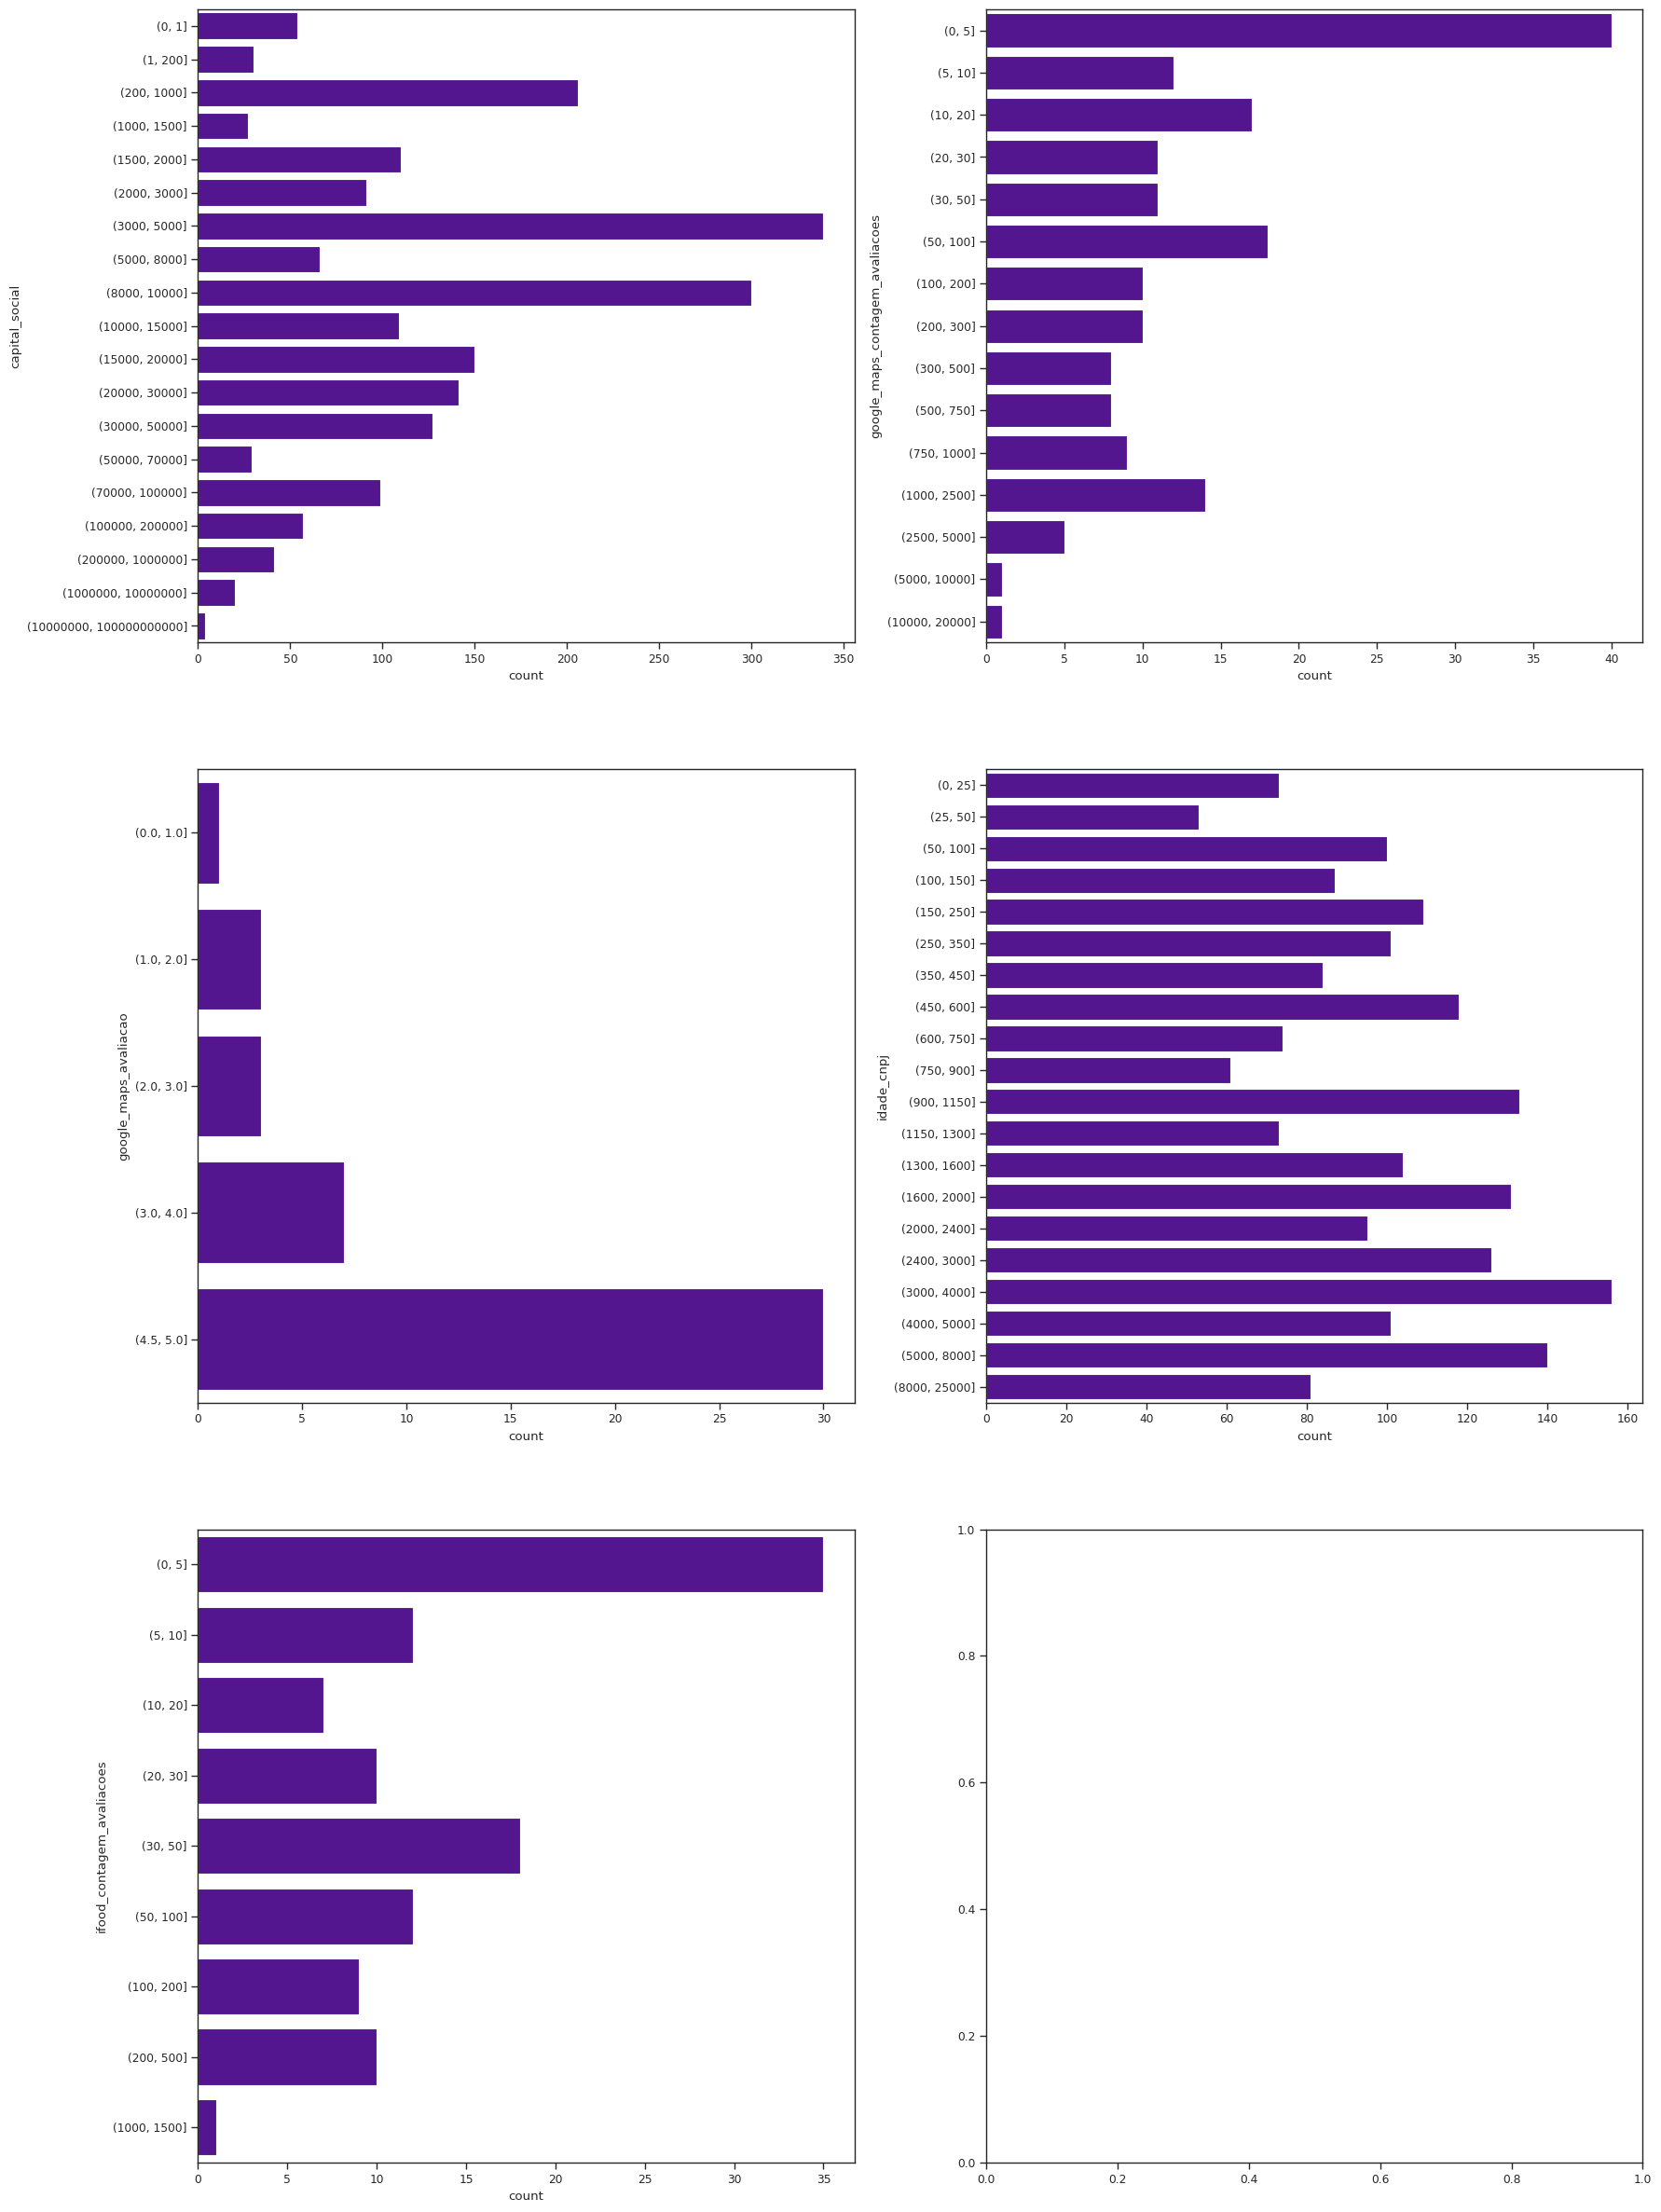

In [22]:
axes = plot.figure(figsize=(20, 30)).subplots(3, 2)

features = ['capital_social', 'idade_cnpj', 'ifood_contagem_avaliacoes', 'google_maps_contagem_avaliacoes', 'google_maps_avaliacao']

for i in range(5):
    feature, ax = features[i], axes[i % 3][i % 2]
    is_float = feature in ('google_maps_avaliacao')
    seaborn.countplot(
        data=leads,
        y=feature,
        order=sort_by_range(leads[feature].dropna().unique(), is_float=is_float),
        ax=ax
    )

<Axes: xlabel='produtos', ylabel='count'>

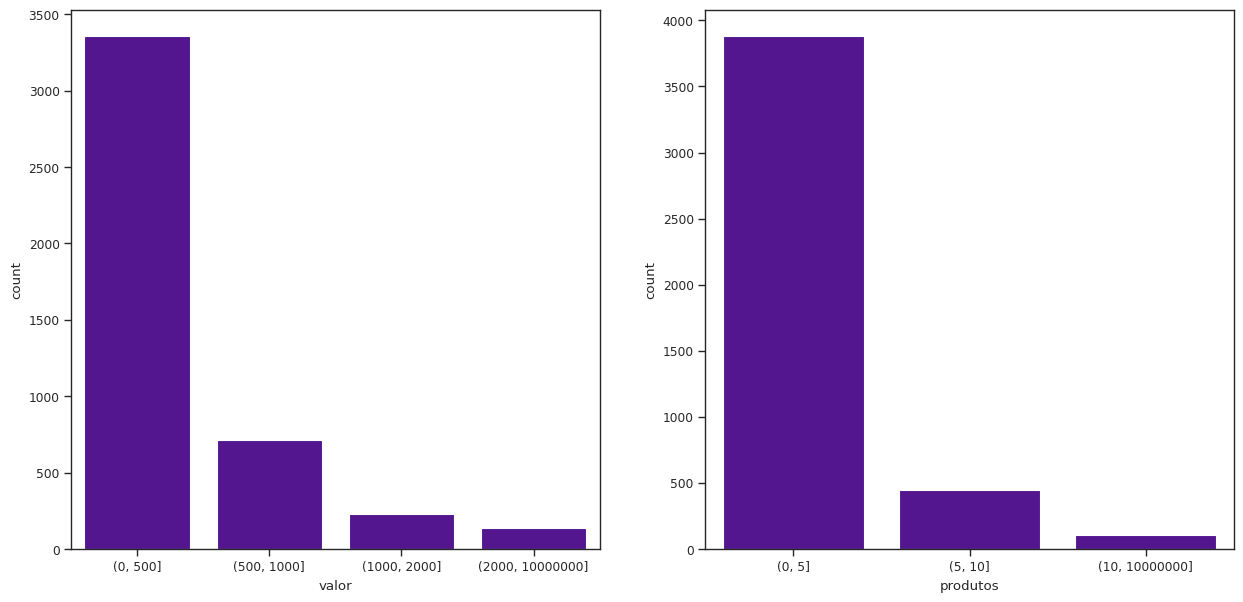

In [23]:
axes = plot.figure(figsize=(15, 7)).subplots(1, 2)

seaborn.countplot(data=pedidos, x='valor', order=sort_by_range(pedidos.valor.dropna().unique()), ax=axes[0])
seaborn.countplot(data=pedidos, x='produtos', order=sort_by_range(pedidos.produtos.dropna().unique()), ax=axes[1])

Outras variáveis categóricas:

<Axes: xlabel='count', ylabel='fonte_cliente'>

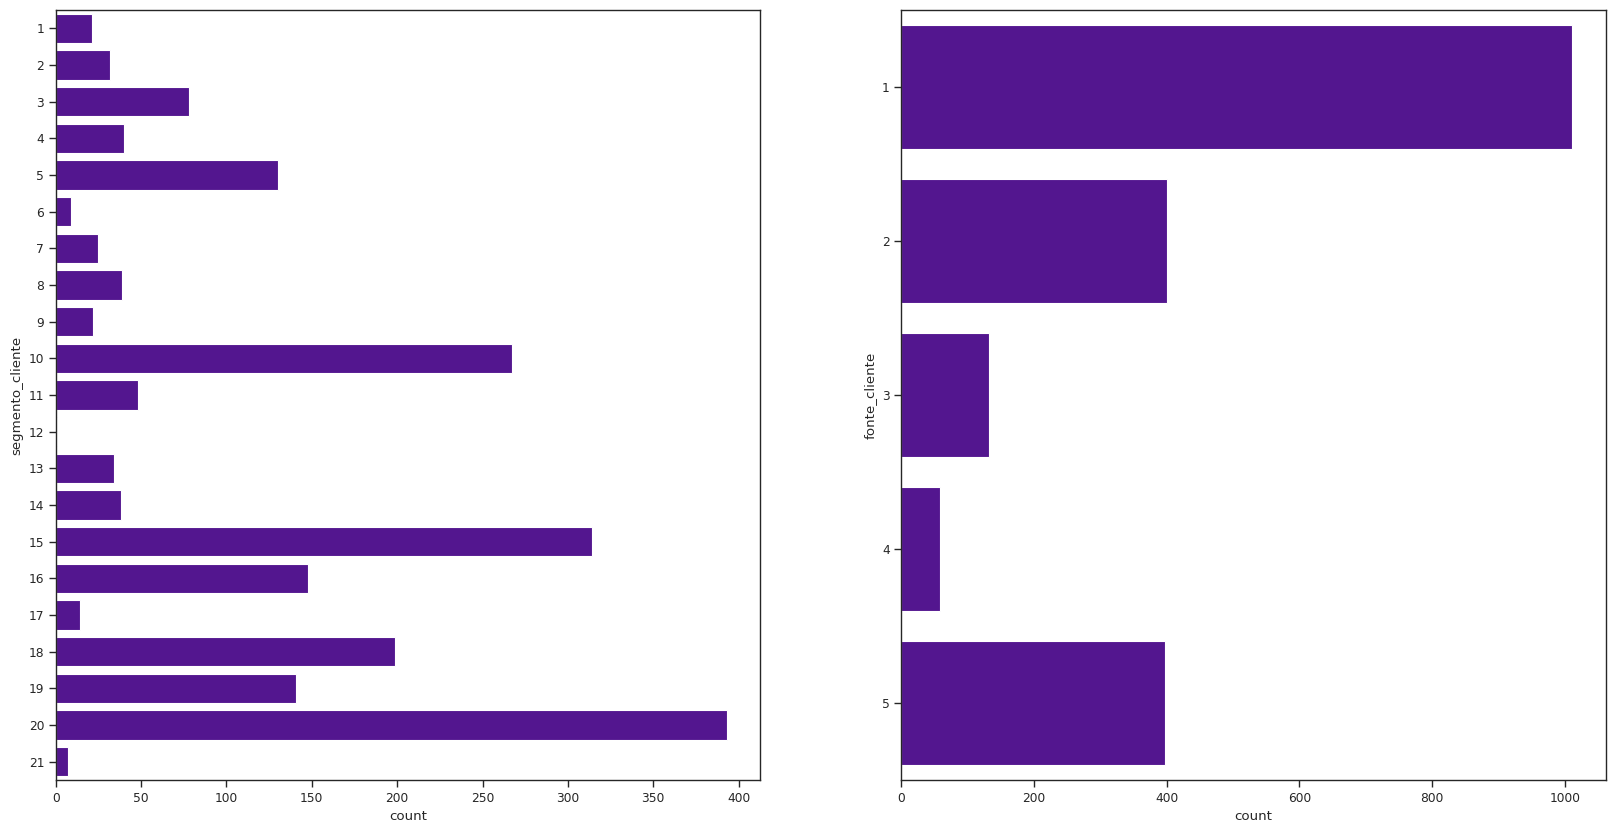

In [24]:
get_number = lambda str: str.split(' ')[1]
segmentos = leads.segmento_cliente.map(get_number)
fontes = leads.fonte_cliente.map(get_number)

ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

seaborn.countplot(data=segmentos.sort_values(key=lambda arr: arr.astype(int)), ax=ax1)
seaborn.countplot(data=fontes.sort_values(key=lambda arr: arr.astype(int)), ax=ax2)

<Axes: xlabel='count', ylabel='ifood_faixa_preco'>

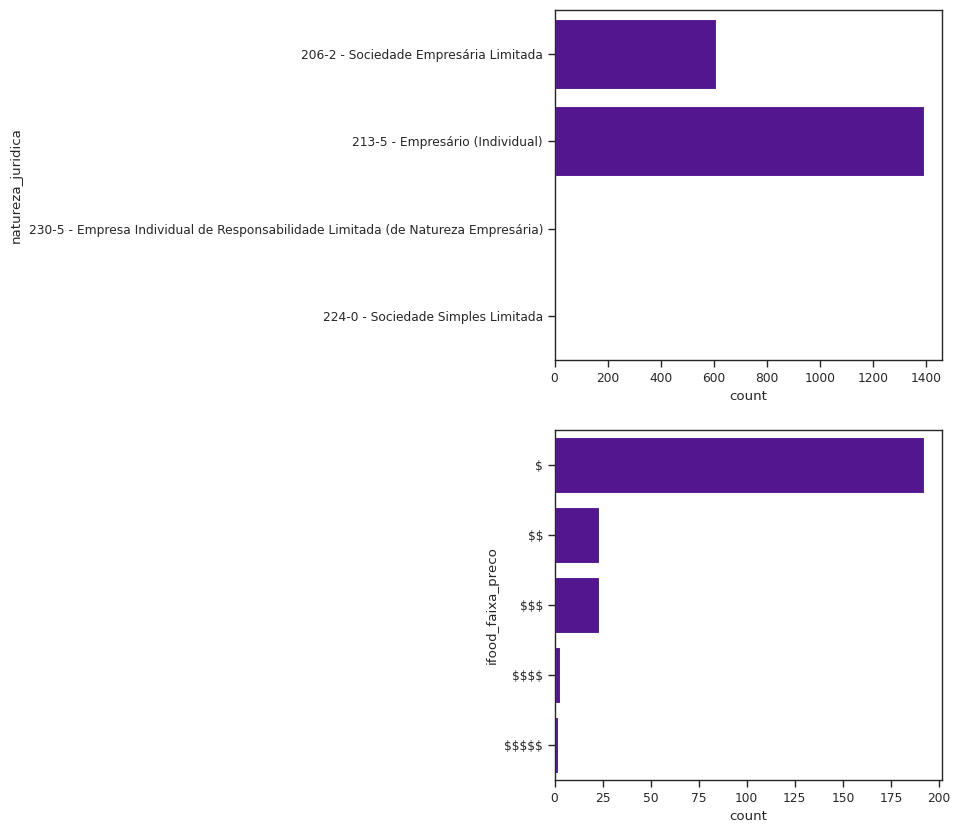

In [25]:
ax1, ax2 = plot.figure(figsize=(5, 10)).subplots(2, 1)

seaborn.countplot(data=leads.natureza_juridica, ax=ax1)
# esse map é pq aparentemente $ é um caracter especial no matplotlib
seaborn.countplot(data=leads.ifood_faixa_preco.dropna().sort_values().map(lambda str: str.replace('$', '\\$')), ax=ax2)

## Análise Bivariada

Avaliando cada um dos clientes cujos pedidos tem `valor` ou `produtos`  nulos:

In [26]:
def extrair_numero(texto):
    if pandas.isna(texto):
        return np.nan
    numeros = re.findall(r'\d+', str(texto))
    if len(numeros) == 2:
        return (float(numeros[0]) + float(numeros[1])) / 2
    return np.nan
clientes_alvo = pedidos[pedidos['valor'].isna() | pedidos['produtos'].isna()]['id_cliente'].unique()
pedidos_filtrados = pedidos[pedidos['id_cliente'].isin(clientes_alvo)].copy()
pedidos_filtrados['valor_numerico'] = pedidos_filtrados['valor'].apply(extrair_numero)

# Clientes que tem valores ou produtos faltando
print("=== HISTÓRICO COMPLETO SEPARADO POR CLIENTE ===")
for id_cliente, dados_do_cliente in pedidos_filtrados.groupby('id_cliente'):
    print(f"\n---> Mostrando todos os pedidos do Cliente ID: {id_cliente}")
    # Usamos o display para mostrar a tabela original bonitinha no notebook
    display(dados_do_cliente[['id_pedido', 'id_cliente', 'valor', 'produtos', 'data_entrega']])

=== HISTÓRICO COMPLETO SEPARADO POR CLIENTE ===

---> Mostrando todos os pedidos do Cliente ID: 5284965822687


,id_pedido,id_cliente,valor,produtos,data_entrega
1749,1582631733956,5284965822687,"(0, 500]","(0, 5]",2024-09-03
1750,5354552944002,5284965822687,"(0, 500]","(0, 5]",2024-09-23
1751,9144766761347,5284965822687,"(0, 500]","(0, 5]",2024-09-24
1752,3328300994554,5284965822687,"(0, 500]","(0, 5]",2024-10-03
1753,5941252653560,5284965822687,"(0, 500]","(0, 5]",2024-10-18
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
1755,7252566720763,5284965822687,"(0, 500]","(0, 5]",2024-11-26
1756,9727236830584,5284965822687,"(500, 1000]","(0, 5]",2024-11-29



---> Mostrando todos os pedidos do Cliente ID: 6829726356717


,id_pedido,id_cliente,valor,produtos,data_entrega
3563,6272749168717,6829726356717,"(0, 500]","(0, 5]",2024-09-01
3564,4585565864108,6829726356717,"(500, 1000]","(5, 10]",2024-09-14
3565,3725217882172,6829726356717,"(1000, 2000]","(10, 10000000]",2024-10-01
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3567,2056586441380,6829726356717,"(0, 500]","(5, 10]",2024-10-13
3568,8643811795861,6829726356717,"(0, 500]","(0, 5]",2024-10-23
3569,7028977447207,6829726356717,"(0, 500]","(5, 10]",2024-10-30



---> Mostrando todos os pedidos do Cliente ID: 8400679696018


,id_pedido,id_cliente,valor,produtos,data_entrega
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10
3604,5457457823905,8400679696018,"(0, 500]","(0, 5]",2024-09-10
3605,7792309100909,8400679696018,"(0, 500]","(0, 5]",2024-09-11
3606,4982714257226,8400679696018,"(0, 500]","(0, 5]",2024-09-12
3607,6587934300674,8400679696018,"(0, 500]","(0, 5]",2024-10-10
3608,3720208144101,8400679696018,"(0, 500]","(0, 5]",2024-10-21
3609,8917394309716,8400679696018,"(0, 500]","(0, 5]",2024-11-06
3610,2460371003704,8400679696018,"(0, 500]","(0, 5]",2024-11-12
3611,9161077679880,8400679696018,"(0, 500]","(0, 5]",2024-11-29
3612,1405173884259,8400679696018,"(0, 500]","(0, 5]",2024-11-29


Contando quantidade de cada valor únicos para atributos 'valor' e 'produtos' em pedidos

In [27]:
contagem_valor = pedidos['valor'].value_counts(dropna=False)

print("=== Quantidade de instâncias para cada valor na coluna 'valor' ===")
display(contagem_valor)

contagem_produtos = pedidos['produtos'].value_counts(dropna=False)

print("\n=== Quantidade de instâncias para cada valor na coluna 'produtos' ===")
display(contagem_produtos)

=== Quantidade de instâncias para cada valor na coluna 'valor' ===


valor
(0, 500]            3361
(500, 1000]          713
(1000, 2000]         230
(2000, 10000000]     134
NaN                    3
Name: count, dtype: int64


=== Quantidade de instâncias para cada valor na coluna 'produtos' ===


produtos
(0, 5]            3885
(5, 10]            446
(10, 10000000]     109
NaN                  1
Name: count, dtype: int64

Avaliando correlação entre valores de 'valor' e 'produto'

In [28]:
#Tabela de Contingência
print("=== TABELA CRUZADA (QUANTIDADE DE COMBINAÇÕES) ===")
tabela_cruzada = pandas.crosstab(pedidos['valor'], pedidos['produtos'])
display(tabela_cruzada)

#Correlação Matemática
pedidos_analise = pedidos.copy()

pedidos_analise['valor_num'] = pedidos_analise['valor'].apply(extrair_numero)
pedidos_analise['produtos_num'] = pedidos_analise['produtos'].apply(extrair_numero)

correlacao = pedidos_analise['valor_num'].corr(pedidos_analise['produtos_num'])

print("\n=== CORRELAÇÃO MATEMÁTICA ===")
print(f"O índice de correlação entre Valor e Produtos é: {correlacao:.4f}")

=== TABELA CRUZADA (QUANTIDADE DE COMBINAÇÕES) ===


produtos,"(0, 5]","(10, 10000000]","(5, 10]"
valor,,,
"(0, 500]",3106,17,238
"(1000, 2000]",168,39,23
"(2000, 10000000]",114,13,7
"(500, 1000]",495,40,178



=== CORRELAÇÃO MATEMÁTICA ===
O índice de correlação entre Valor e Produtos é: 0.0827


Visualizando tudo isso em gráfico e matriz

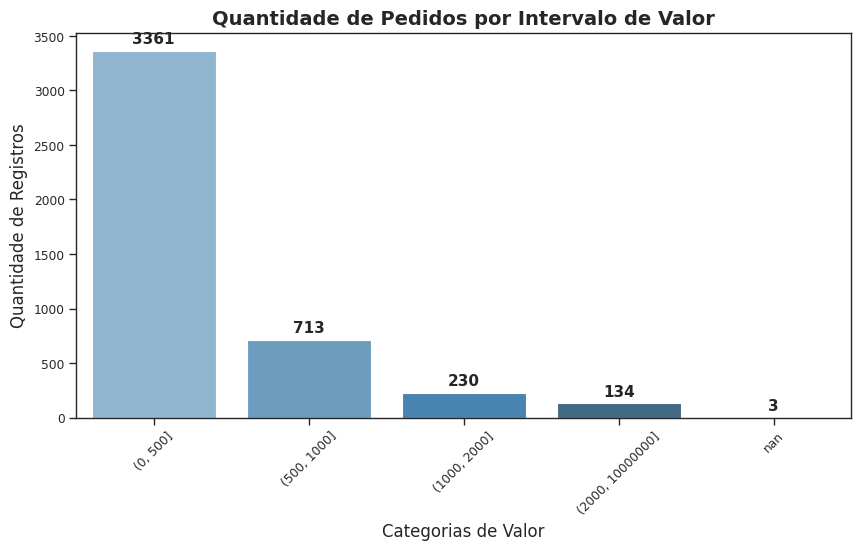

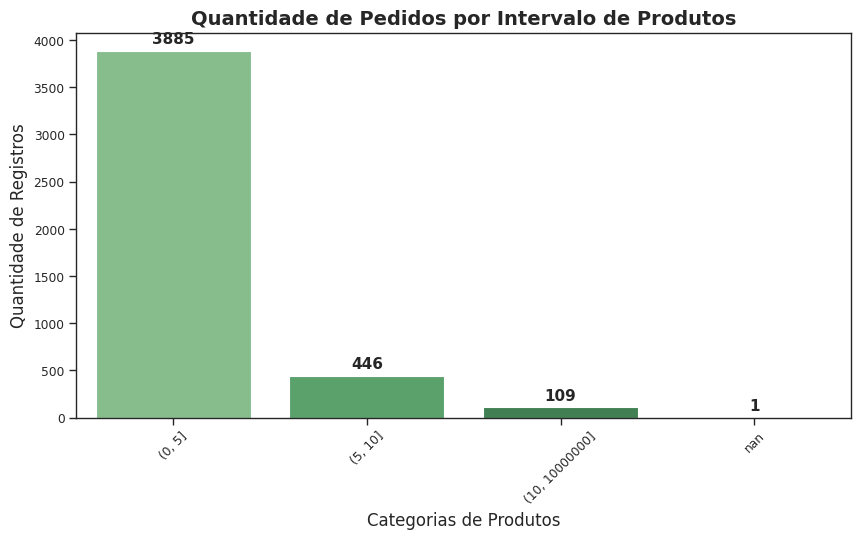

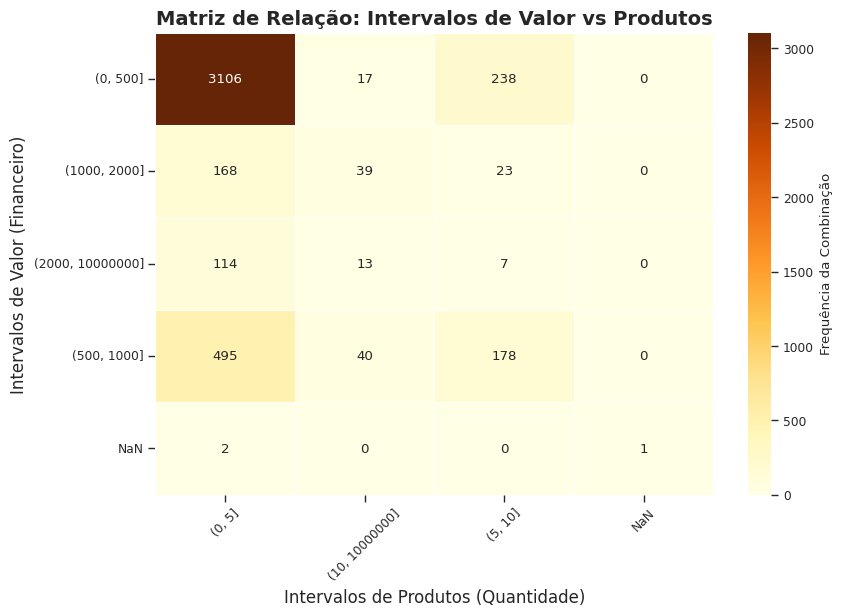

In [29]:
#Contagem da coluna 'valor' com os números no topo
plot.figure(figsize=(10, 5))
contagem_valor = pedidos['valor'].value_counts(dropna=False)

ax1 = seaborn.barplot(
    x=contagem_valor.index.astype(str),
    y=contagem_valor.values,
    hue=contagem_valor.index.astype(str),
    palette="Blues_d",
    legend=False
)

for container in ax1.containers:
    ax1.bar_label(container, fontsize=11, padding=3, fontweight='bold')

plot.title("Quantidade de Pedidos por Intervalo de Valor", fontsize=14, fontweight='bold')
plot.xlabel("Categorias de Valor", fontsize=12)
plot.ylabel("Quantidade de Registros", fontsize=12)
plot.xticks(rotation=45)
plot.show()


#Contagem da coluna 'produtos' com os números no topo
plot.figure(figsize=(10, 5))
contagem_produtos = pedidos['produtos'].value_counts(dropna=False)

ax2 = seaborn.barplot(
    x=contagem_produtos.index.astype(str),
    y=contagem_produtos.values,
    hue=contagem_produtos.index.astype(str),
    palette="Greens_d",
    legend=False
)

for container in ax2.containers:
    ax2.bar_label(container, fontsize=11, padding=3, fontweight='bold')

plot.title("Quantidade de Pedidos por Intervalo de Produtos", fontsize=14, fontweight='bold')
plot.xlabel("Categorias de Produtos", fontsize=12)
plot.ylabel("Quantidade de Registros", fontsize=12)
plot.xticks(rotation=45)
plot.show()


#Mapa de Calor (Relação entre os Intervalos literais)
tabela_cruzada = pandas.crosstab(
    pedidos['valor'].fillna('NaN').astype(str),
    pedidos['produtos'].fillna('NaN').astype(str)
)

plot.figure(figsize=(9, 6))

seaborn.heatmap(
    tabela_cruzada,
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    linewidths=0.5,
    cbar_kws={'label': 'Frequência da Combinação'}
)

plot.title("Matriz de Relação: Intervalos de Valor vs Produtos", fontsize=14, fontweight='bold')
plot.xlabel("Intervalos de Produtos (Quantidade)", fontsize=12)
plot.ylabel("Intervalos de Valor (Financeiro)", fontsize=12)
plot.xticks(rotation=45)
plot.show()

<Axes: xlabel='count', ylabel='segmento_cliente'>

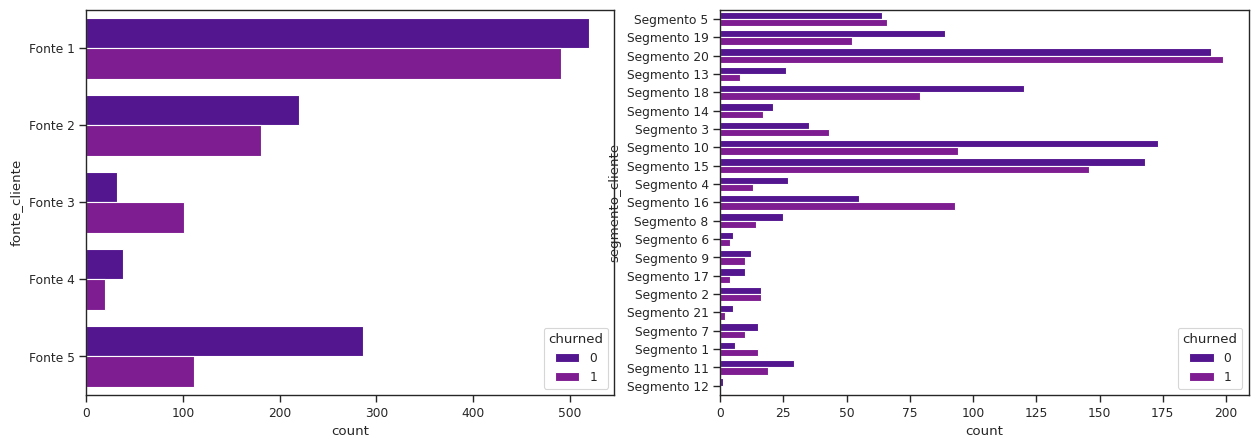

In [30]:
ax1, ax2 = plot.figure(figsize=(15, 5)).subplots(1, 2)
seaborn.countplot(data=leads,hue='churned',y='fonte_cliente',order=sorted(leads.fonte_cliente.unique()), ax=ax1)
seaborn.countplot(data=leads,hue='churned',y='segmento_cliente',ax=ax2)

> Vou ver em fonte cliente e segmento, mas acho importante ver em relação ao tamanho também

In [31]:
leads.groupby('segmento_cliente').churned.agg(['count']).sort_values('count')

,count
segmento_cliente,
Segmento 12,1
Segmento 21,7
Segmento 6,9
Segmento 17,14
Segmento 1,21
Segmento 9,22
Segmento 7,25
Segmento 2,32
Segmento 13,34


> O Segmente 1 tem a maior taxa de churn, mas tem pouco cliente. Já o segmente 16 tem uma taxa de churn alta também e cerca de 148 clientes

In [32]:
leads.groupby('fonte_cliente').churned.agg(['count']).sort_values('count')

,count
fonte_cliente,
Fonte 4,58
Fonte 3,133
Fonte 5,397
Fonte 2,401
Fonte 1,1011


Text(0.5, 1.0, 'Está no iFood?')

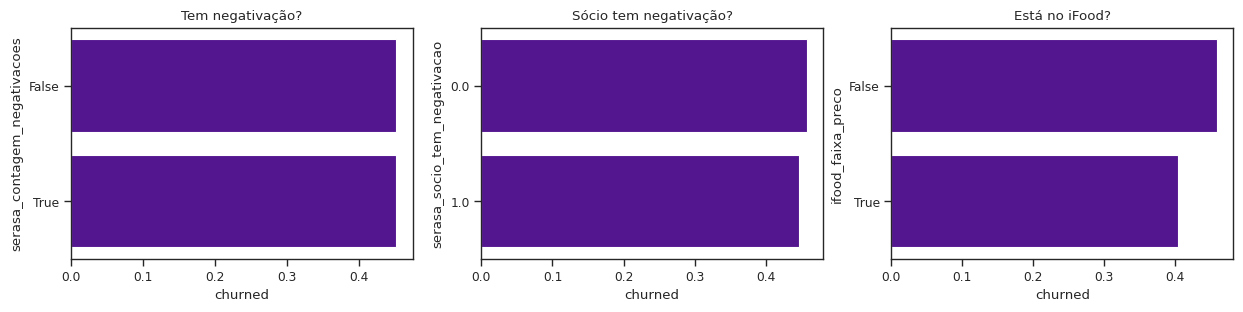

In [33]:
ax1, ax2, ax3 = plot.figure(figsize=(15, 3)).subplots(1, 3)

seaborn.barplot(x=leads.churned, y=leads.serasa_contagem_negativacoes > 0, orient='h',errorbar=None, ax=ax1)
seaborn.barplot(x=leads.churned, y=leads.serasa_socio_tem_negativacao, orient='h',errorbar=None, ax=ax2)
seaborn.barplot(x=leads.churned, y=leads.ifood_faixa_preco.notna(),orient='h',errorbar=None, ax=ax3)

ax1.set_title('Tem negativação?')
ax2.set_title('Sócio tem negativação?')
ax3.set_title('Está no iFood?')

> Pensei que ter negativação de alguma forma iria interferir no churn, mas não é uma diferença grotesca

### Tratamento dos pedidos e variáveis por cliente

Funções de tratamento de faixas e nulos para colunas de pedido

In [34]:
# '(0, 500]' -> 250
def ponto_medio_pedido(faixa):
    if pandas.isna(faixa):
        return np.nan
    baixo, alto = [float(x) for x in faixa.strip('()[]').split(',')]
    if alto >= 10_000_000:        # o teto não significa nada
        return baixo              # usa o limite inferior
    return (baixo + alto) / 2     # faixa fechada - ponto medio

pedidos['valor_num'] = pedidos['valor'].map(ponto_medio_pedido)
pedidos['produtos_num'] = pedidos['produtos'].map(ponto_medio_pedido)

display(pedidos[['valor', 'valor_num']].drop_duplicates().sort_values('valor_num'))
display(pedidos[['produtos', 'produtos_num']].drop_duplicates().sort_values('produtos_num'))


,valor,valor_num
0,"(0, 500]",250.0
4,"(500, 1000]",750.0
27,"(1000, 2000]",1500.0
5,"(2000, 10000000]",2000.0
1754,NaN,NaN


,produtos,produtos_num
0,"(0, 5]",2.5
11,"(5, 10]",7.5
27,"(10, 10000000]",10.0
3603,NaN,NaN


In [35]:
# tratamento dos 3 nulos encontrados
nulos = pedidos['valor_num'].isna() | pedidos['produtos_num'].isna()
print('ANTES:')
display(pedidos.loc[nulos, ['id_pedido', 'id_cliente', 'valor_num', 'produtos_num']])

for coluna in ['valor_num', 'produtos_num']:
    # devolve a mediana do cliente dela
    mediana_do_cliente = pedidos.groupby('id_cliente')[coluna].transform('median')
    pedidos[coluna] = pedidos[coluna].fillna(mediana_do_cliente).fillna(pedidos[coluna].median())

print('DEPOIS:')
display(pedidos.loc[nulos, ['id_pedido', 'id_cliente', 'valor_num', 'produtos_num']])

ANTES:


,id_pedido,id_cliente,valor_num,produtos_num
1754,3651192517370,5284965822687,NaN,2.5
3566,8540620592324,6829726356717,NaN,2.5
3603,9279195172130,8400679696018,NaN,NaN


DEPOIS:


,id_pedido,id_cliente,valor_num,produtos_num
1754,3651192517370,5284965822687,250.0,2.5
3566,8540620592324,6829726356717,250.0,2.5
3603,9279195172130,8400679696018,250.0,2.5


In [36]:
# vários pedidos no mesmo dia contam como 1 dia
pedidos['data'] = pandas.to_datetime(pedidos['data_entrega'])
print('de', pedidos['data'].min().date(), 'até', pedidos['data'].max().date())

de 2024-09-01 até 2024-12-01


Resumir o comportamento de cada cliente

In [37]:
DATA_REF = pedidos['data'].max()

def intervalo_medio(datas):
    dias = datas.drop_duplicates().sort_values()     # só dias distintos, em ordem
    return dias.diff().dt.days.mean()                # diferença entre dias seguidos, em média (NaN se só há 1 dia)

# agrupa os pedidos por cliente e calcula vários resumos de uma vez
por_cliente = pedidos.groupby('id_cliente').agg(
    n_pedidos=('id_pedido', 'count'),
    n_dias_com_pedido=('data', 'nunique'),
    valor_min=('valor_num', 'min'),
    valor_medio=('valor_num', 'mean'),
    valor_mediano=('valor_num', 'median'),
    valor_max=('valor_num', 'max'),
    produtos_min=('produtos_num', 'min'),
    produtos_medio=('produtos_num', 'mean'),
    produtos_mediano=('produtos_num', 'median'),
    produtos_max=('produtos_num', 'max'),
    ultima_data=('data', 'max'),
)

por_cliente['recencia_dias'] = (DATA_REF - por_cliente['ultima_data']).dt.days
por_cliente['intervalo_medio_dias'] = pedidos.groupby('id_cliente')['data'].apply(intervalo_medio)
por_cliente = por_cliente.drop(columns='ultima_data').reset_index()

print('linhas:', len(por_cliente), '| clientes distintos:', por_cliente['id_cliente'].nunique())
por_cliente.head(10)

linhas: 1000 | clientes distintos: 1000


,id_cliente,n_pedidos,n_dias_com_pedido,valor_min,valor_medio,valor_mediano,valor_max,produtos_min,produtos_medio,produtos_mediano,produtos_max,recencia_dias,intervalo_medio_dias
0,1015124383998,5,5,250.0,450.000000,250.0,750.0,2.5,2.500000,2.5,2.5,33,10.000000
1,1015377772889,1,1,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,41,NaN
2,1027001713204,13,10,250.0,557.692308,250.0,1500.0,2.5,4.038462,2.5,10.0,21,7.777778
3,1028541889208,5,4,250.0,350.000000,250.0,750.0,2.5,2.500000,2.5,2.5,2,25.666667
4,1048076190944,8,7,250.0,312.500000,250.0,750.0,2.5,2.500000,2.5,2.5,2,14.333333
5,1056896735732,3,3,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,18,14.500000
6,1072013408481,8,8,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,6,10.000000
7,1074690105832,2,2,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,34,6.000000
8,1075117254630,2,2,250.0,500.000000,500.0,750.0,7.5,7.500000,7.5,7.5,4,44.000000
9,1082403104432,13,11,250.0,442.307692,250.0,750.0,2.5,6.346154,7.5,7.5,5,8.300000


In [38]:
base_clientes = leads.merge(por_cliente, on='id_cliente', how='left', validate='one_to_one')

# flag - lead tem pedido ?
base_clientes['tem_pedido'] = base_clientes['n_pedidos'].notna().astype(int)

assert len(base_clientes) == len(leads)        # associa o conjunto de pedidos a um cliente - msm qnt de linhas agr
print('linhas em base_clientes:', len(base_clientes), '| taxa de churn:', round(base_clientes['churned'].mean(), 3))
print('clientes com pedido:', base_clientes['tem_pedido'].sum(), 'de', len(base_clientes))

# só os clientes com pedido
com_pedido = base_clientes[base_clientes['tem_pedido'] == 1]


linhas em base_clientes: 2000 | taxa de churn: 0.452
clientes com pedido: 1000 de 2000


1000 dos clientes não compraram - nulo estrutural tratado com flag

### Bivariada - pedidos vs churn

Variáveis numéricas (de pedidos) comparadas com o churn por Spearman e por faixas

               n  taxa_churn
tem_pedido                  
0           1000       0.463
1           1000       0.441


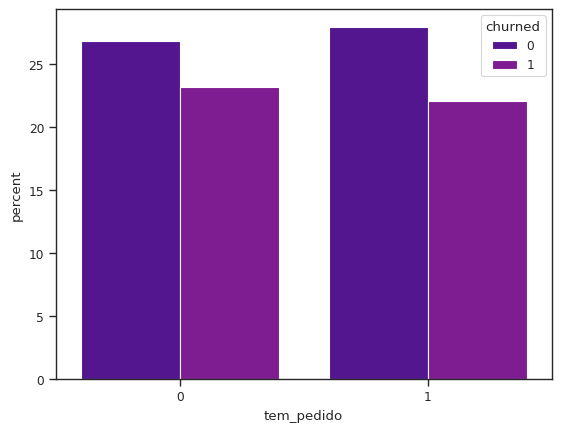

In [39]:
print(base_clientes.groupby('tem_pedido')['churned'].agg(n='count', taxa_churn='mean').round(3))
_ = seaborn.countplot(data=base_clientes, x='tem_pedido', hue='churned', stat='percent')

- Quem já fez algum pedido tem uma chance um pouquinho maior de não dar churn

,n,Spearman,p-valor
variável,,,
n_pedidos,1000,-0.498,0.000
n_dias_com_pedido,1000,-0.498,0.000
recencia_dias,1000,0.444,0.000
produtos_max,1000,-0.196,0.000
valor_max,1000,-0.179,0.000
produtos_medio,1000,-0.176,0.000
intervalo_medio_dias,694,0.157,0.000
valor_medio,1000,-0.140,0.000
valor_mediano,1000,-0.038,0.228


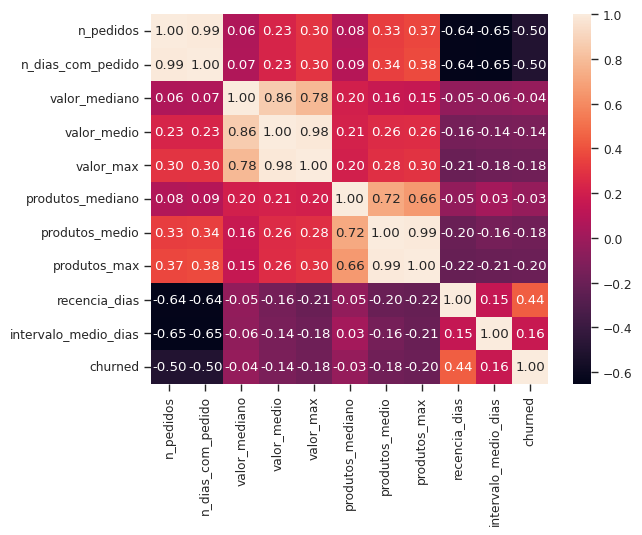

In [40]:
colunas = ['n_pedidos', 'n_dias_com_pedido', 'valor_mediano', 'valor_medio', 'valor_max',
           'produtos_mediano', 'produtos_medio', 'produtos_max', 'recencia_dias', 'intervalo_medio_dias']

# Spearman de cada variável com o churn
# positivo - quanto maior a variável, mais churn | negativo - quanto maior a variável, menos churn
linhas = []
for coluna in colunas:
    dados = com_pedido[[coluna, 'churned']].dropna()
    rho, p = stats.spearmanr(dados[coluna], dados['churned'])
    linhas.append({'variável': coluna, 'n': len(dados), 'Spearman': rho, 'p-valor': p})

seaborn.heatmap(data=base_clientes[colunas + ['churned']].corr(method='spearman'), annot=True, fmt='.2f')
pandas.DataFrame(linhas).set_index('variável').sort_values('Spearman', key=abs, ascending=False).round(3)

- As variáveis com maior relação com o churn são `n_pedidos` (Spearman ≈ −0,50), `n_dias_com_pedido` (≈ −0,50) e `recencia_dias` (≈ +0,44) - quem compra pouco e há muito tempo tende a dar churn.

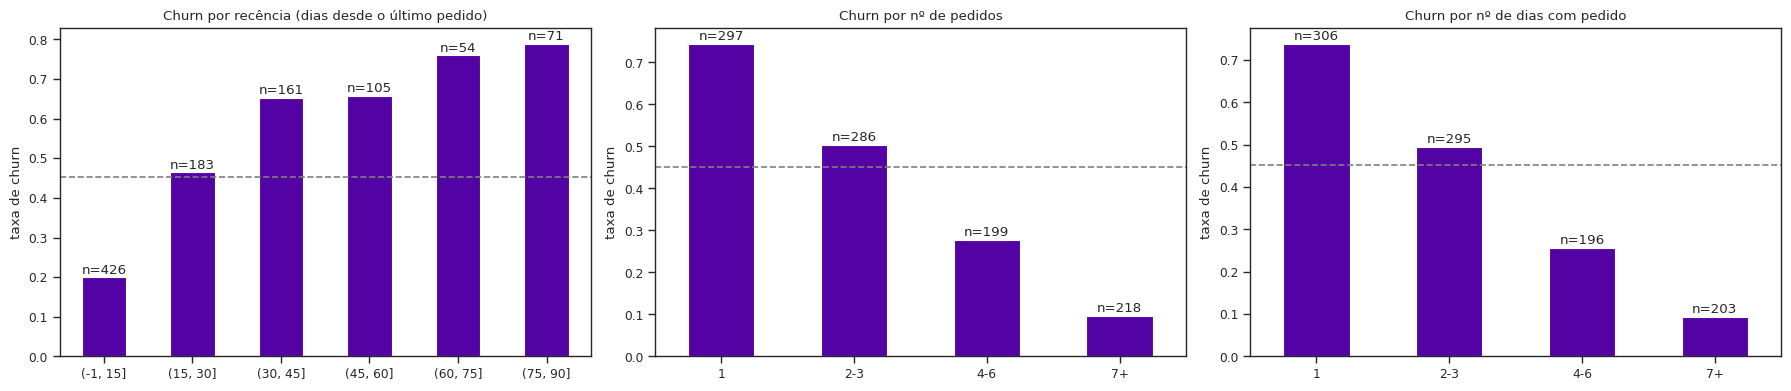

In [41]:
com_pedido = com_pedido.copy()

com_pedido['faixa_recencia'] = pandas.cut(com_pedido['recencia_dias'], [-1, 15, 30, 45, 60, 75, 90])
com_pedido['faixa_pedidos'] = pandas.cut(com_pedido['n_pedidos'], [0, 1, 3, 6, 100], labels=['1', '2-3', '4-6', '7+'])
com_pedido['faixa_dias'] = pandas.cut(com_pedido['n_dias_com_pedido'], [0, 1, 3, 6, 100], labels=['1', '2-3', '4-6', '7+'])

fig, axes = plot.subplots(1, 3, figsize=(18, 4))
for ax, coluna, titulo in [(axes[0], 'faixa_recencia', 'Churn por recência (dias desde o último pedido)'),
                           (axes[1], 'faixa_pedidos', 'Churn por nº de pedidos'),
                           (axes[2], 'faixa_dias', 'Churn por nº de dias com pedido')]:
    tabela = com_pedido.groupby(coluna, observed=True)['churned'].agg(n='count', taxa='mean')
    tabela['taxa'].plot(kind='bar', ax=ax, rot=0)
    ax.axhline(leads['churned'].mean(), color='gray', linestyle='--')    # linha tracejada = taxa geral dos leads
    for i, (n, taxa) in enumerate(zip(tabela['n'], tabela['taxa'])):
        ax.text(i, taxa + 0.01, f'n={n}', ha='center')
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('taxa de churn')
plot.tight_layout()
plot.show()

Dá para perceber que n_pedidos e n_dias_com_pedido são bastante correlacionadas, e, portanto, redundantes.

### Bivariada: cadastro vs churn

Variáveis categóricas (do cadastro) comparadas com o churn: taxa de churn de cada categoria e teste qui-quadrado. `p < 0,05` indica relação com o churn. 

In [42]:
def analise_categorica(coluna, minimo=30):
    serie = leads[coluna].astype(str)
    contagem = serie.value_counts()
    serie = serie.where(serie.map(contagem) >= minimo, 'Outras')     # categorias com poucos leads viram 'Outras'

    # quantos leads e qual a taxa de churn de cada categoria
    tabela = leads.groupby(serie)['churned'].agg(leads='count', taxa_churn='mean')
    tabela['taxa_churn'] = (tabela['taxa_churn'] * 100).round(1)

    # qui-quadrado
    p = stats.chi2_contingency(pandas.crosstab(serie, leads['churned']))[1]
    conclusao = 'há relação com o churn' if p < 0.05 else 'sem relação clara com o churn'
    print(f'{coluna}: p-valor = {p:.4f} -> {conclusao}')

    return tabela.sort_values('taxa_churn', ascending=False)

In [43]:
display(analise_categorica('fonte_cliente'))
display(analise_categorica('segmento_cliente'))

fonte_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
fonte_cliente,,
Fonte 3,133,75.9
Fonte 1,1011,48.6
Fonte 2,401,45.1
Fonte 4,58,34.5
Fonte 5,397,28.0


segmento_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
segmento_cliente,,
Segmento 16,148,62.8
Segmento 3,78,55.1
Segmento 5,130,50.8
Segmento 20,393,50.6
Segmento 2,32,50.0
Segmento 15,314,46.5
Outras,99,45.5
Segmento 14,38,44.7
Segmento 18,199,39.7


In [44]:
leads['cnae_divisao'] = leads['cnae_codigo'].str[:2]      # 2 primeiros dígitos = divisão

display(analise_categorica('natureza_juridica'))
display(analise_categorica('idade_cnpj'))
display(analise_categorica('cnae_divisao'))

natureza_juridica: p-valor = 0.0042 -> há relação com o churn


,leads,taxa_churn
natureza_juridica,,
213-5 - Empresário (Individual),1390,47.4
206-2 - Sociedade Empresária Limitada,607,40.4
Outras,3,0.0


idade_cnpj: p-valor = 0.8056 -> sem relação clara com o churn


,leads,taxa_churn
idade_cnpj,,
"(3000, 4000]",156,52.6
"(100, 150]",87,51.7
"(50, 100]",100,50.0
"(2400, 3000]",126,49.2
"(150, 250]",109,47.7
"(1600, 2000]",131,47.3
"(1150, 1300]",73,46.6
"(900, 1150]",133,46.6
"(2000, 2400]",95,45.3


cnae_divisao: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
cnae_divisao,,
77,387,50.1
53,1225,47.0
Outras,91,42.9
39,265,32.8
74,32,25.0


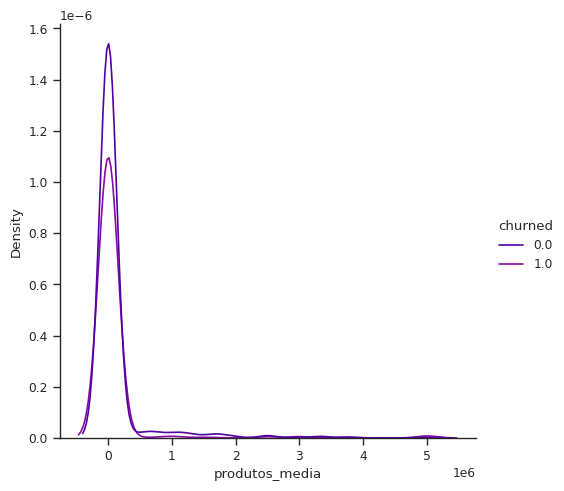

In [45]:
from numpy import nan, average

def pegar_media(intervalo: str) -> float:
    if not isinstance(intervalo, str):
        return nan
    a, b = intervalo[1:-1].split(', ')
    return 0.5*(float(a)+float(b))

joined['produtos_media'] = joined.produtos.apply(pegar_media)

medias_produto_por_cliente = joined.get(['id_cliente', 'produtos_media', 'churned']).groupby('id_cliente').aggregate(average)

seaborn.displot(data=medias_produto_por_cliente, x='produtos_media', hue='churned', kind='kde')

<Axes: >

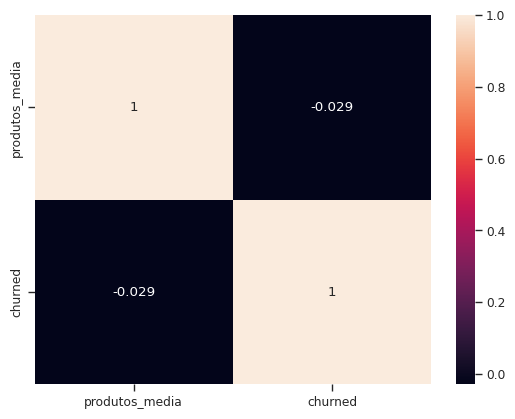

In [46]:
seaborn.heatmap(medias_produto_por_cliente.corr(), annot=True)

,valor_media,churned
id_cliente,,
1011943995012,NaN,1.0
1015124383998,450.000000,0.0
1015377772889,250.000000,0.0
1025473400743,NaN,1.0
1027001713204,557.692308,0.0
...,...,...
9981750130537,NaN,1.0
9983300803445,250.000000,1.0
9987002545841,500.000000,1.0


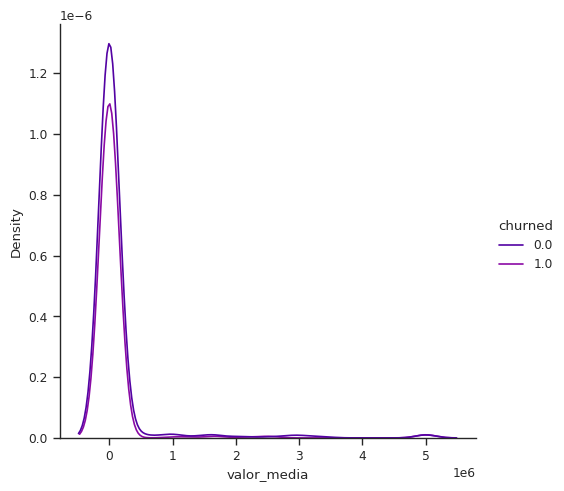

In [47]:
joined['valor_media'] = joined.valor.apply(pegar_media)

medias_valor_por_cliente = joined.get(['id_cliente', 'valor_media', 'churned']).groupby('id_cliente').aggregate(average)

seaborn.displot(data=medias_valor_por_cliente, x='valor_media', hue='churned', kind='kde')
medias_valor_por_cliente

<Axes: >

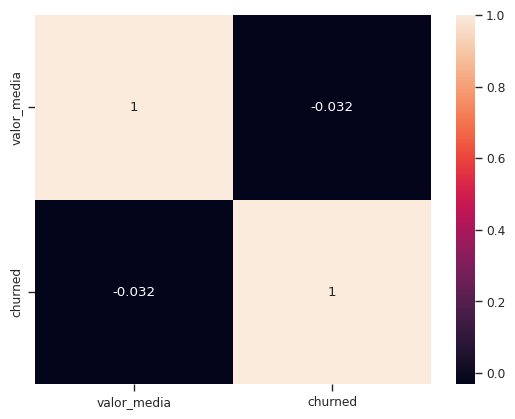

In [48]:
seaborn.heatmap(medias_valor_por_cliente.corr(), annot=True)

### Pontos que anotamos após perguntar à monitora

- churn mais prejudicial 
- Quanto varia, um cara que compra 10000 sempre, agora compra bem menos
- Tempo médio de compra
- Idade cnpj: 'empresas jovens'
- Pessoa sempre compra há duas semanas e não tá comprando agora (Clientes que tá sempre comprando e clientes que comprou uma vez na vida)
- relacionamento entre tempo entre pedidos e churn (se uma pessoa compra a cada mes, ela tem uma chance de churn maior que alguem que compra a cada semana?)
- Ver variância de valor (um cliente que vai comprando mais ou menos com o tempo tem chance maior de dar churn?)
- Ver as coisas de forma catégorica --> intervalo
- contagem de pedidos no total por cliente vs churn

---

Pensando em uma forma de calcular a frequência de pedidos de um cliente

In [49]:
def get_frequencia_pedido(cliente: int) -> float:
    pedidos_do_cliente = pedidos[pedidos.id_cliente == cliente]
    
    if pedidos_do_cliente.empty:
        return -np.inf # se o cliente nunca pediu nada antes

    pedidos_do_cliente.data_entrega = pedidos_do_cliente.data_entrega.apply(pandas.to_datetime)

    datas = sorted(pedidos_do_cliente.data_entrega)
    deltas = []
    
    for i in range(len(datas) - 1, 0, -1):
        delta = datas[i] - datas[i - 1]
        deltas.append(delta.days)

    # se é o primeiro pedido do cliente isso vai ser 0 pq nao vai ter deltas
    return np.average(deltas) if len(deltas) > 0 else 0.0

for cliente in joined.id_cliente.unique():
    joined.loc[joined.id_cliente == cliente, 'frequencia_compras'] = get_frequencia_pedido(cliente)

joined.frequencia_compras

/tmp/ipykernel_120031/1537859148.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pedidos_do_cliente.data_entrega = pedidos_do_cliente.data_entrega.apply(pandas.to_datetime)
/tmp/ipykernel_120031/1537859148.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pedidos_do_cliente.data_entrega = pedidos_do_cliente.data_entrega.apply(pandas.to_datetime)
/tmp/ipykernel_120031/1537859148.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,

0       -inf
1       -inf
2       9.75
3       9.75
4       9.75
        ... 
5436    0.00
5437    -inf
5438    -inf
5439    0.00
5440    -inf
Name: frequencia_compras, Length: 5441, dtype: float64

<Axes: ylabel='frequencia_compras'>

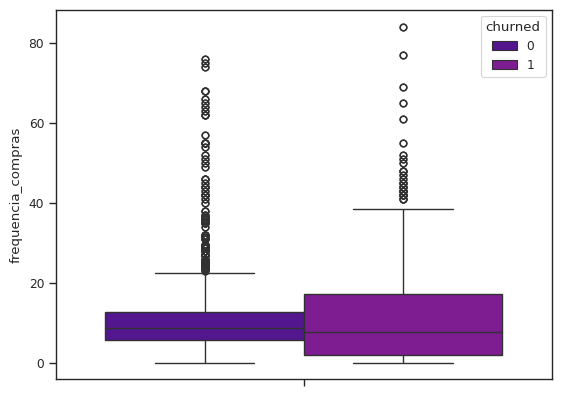

In [50]:
seaborn.boxplot(data=joined, y='frequencia_compras', hue='churned')

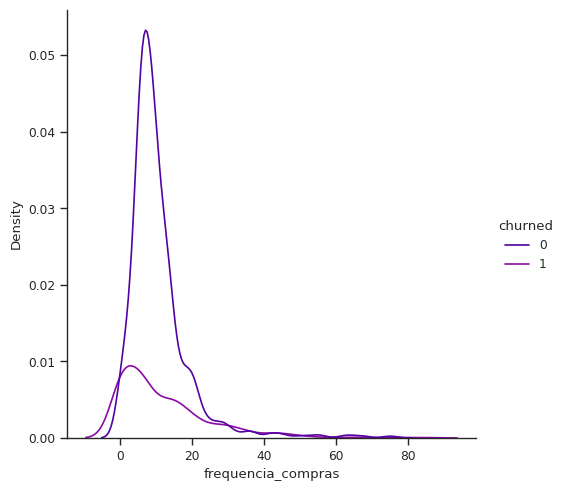

In [51]:
seaborn.displot(data=joined, x='frequencia_compras', hue='churned', kind='kde')

- Esses gráficos desconsideram clientes que nunca pediram nada antes
- Os clientes que tem frequencia = 0 fizeram apenas um pedido (não têm nenhuma frequência)
- Tem um pico na densidade de churn quando a frequência está em torno de 0, ou seja, **quem pede pela primeira vez tem uma chance muito maior de churn**

<Axes: xlabel='es', ylabel='count'>

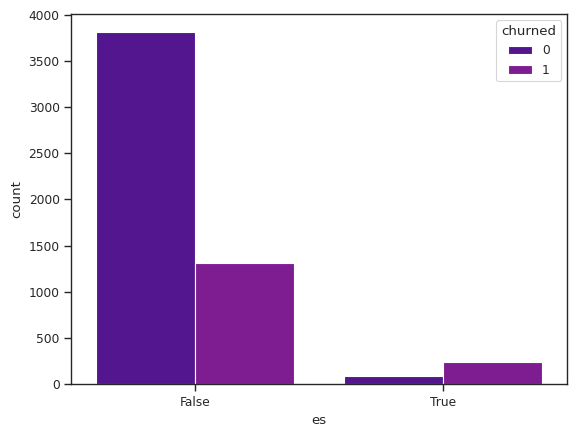

In [52]:
joined['es'] = joined.frequencia_compras.apply(lambda v: v == 0)

seaborn.countplot(data=joined, x='es', hue='churned')

Vamos realizar um corte em idade cnpj, porque fica melhor de analisar do que com todas as faixas.

In [ ]:
joined.head()

,id_cliente,uf,municipio,segmento_cliente,natureza_juridica,fonte_cliente,cnae_codigo,capital_social,idade_cnpj,serasa_contagem_negativacoes,...,google_maps_tem_website,churned,id_pedido,valor,produtos,data_entrega,produtos_media,valor_media,frequencia_compras,es
0,3005277736677,CE,FORTALEZA,Segmento 5,206-2 - Sociedade Empresária Limitada,Fonte 5,53.23-6-24,"(70000, 100000]","(8000, 25000]",0.0,...,1.0,0,NaN,NaN,NaN,NaN,NaN,NaN,-inf,False
1,4227406830370,CE,FORTALEZA,Segmento 19,206-2 - Sociedade Empresária Limitada,Fonte 5,53.23-6-24,"(3000, 5000]","(5000, 8000]",0.0,...,1.0,0,NaN,NaN,NaN,NaN,NaN,NaN,-inf,False
2,4524631448006,CE,FORTALEZA,Segmento 20,206-2 - Sociedade Empresária Limitada,Fonte 5,53.23-6-24,"(8000, 10000]","(5000, 8000]",14.0,...,1.0,0,9.148363e+12,"(0, 500]","(0, 5]",2024-09-12,2.5,250.0,9.75,False
3,4524631448006,CE,FORTALEZA,Segmento 20,206-2 - Sociedade Empresária Limitada,Fonte 5,53.23-6-24,"(8000, 10000]","(5000, 8000]",14.0,...,1.0,0,3.210783e+12,"(0, 500]","(0, 5]",2024-09-30,2.5,250.0,9.75,False
4,4524631448006,CE,FORTALEZA,Segmento 20,206-2 - Sociedade Empresária Limitada,Fonte 5,53.23-6-24,"(8000, 10000]","(5000, 8000]",14.0,...,1.0,0,1.115790e+12,"(0, 500]","(0, 5]",2024-10-04,2.5,250.0,9.75,False


In [54]:
def primeiro_num(intervalo: str) -> float:
    if not isinstance(intervalo, str):
        return nan
    a, _ = intervalo[1:-1].split(', ')
    return float(a)

leads['idade_min'] = leads['idade_cnpj'].apply(primeiro_num)
primeiro_num("(600, 750]")

600.0

> A idade média das empresas ativas é de 8 anos, com uma taxa de mortalidade que aumenta nos primeiros anos de atividade. Cerca de 77,9% das empresas encerram suas operações antes de completar 4 anos, e menos de 1% chegam a completar 10 anos de vida.(https://noticias.gs1br.org/60-milhoes-de-empresas-ja-foram-abertas/)

Com base nisso, vamos considerar menor que 4 anos como empresa nova e mais como empresa antiga. tem a faixa (1300,1600] que fica dos dos lados

In [55]:
leads['tempo_de_casa'] = pandas.cut(leads['idade_min'],bins=[-np.inf, 1600, np.inf],labels=['nova', 'antiga'],right=False)

pandas.crosstab(leads['churned'],leads['tempo_de_casa'],normalize=False)

tempo_de_casa,nova,antiga
churned,,
0,650,446
1,520,384


In [56]:
#vendo como podemos dividir
leads['serasa_credores'].unique()

#separados por virgula
leads['qtd_credores'] = leads['serasa_credores'].str.split(', ').str.len()
leads['qtd_credores'] = leads['qtd_credores'].fillna(0)

leads['qtd_credores'].value_counts(dropna=False).sort_index()

qtd_credores
0.0    1810
1.0     148
2.0      24
3.0      11
4.0       4
5.0       1
6.0       1
7.0       1
Name: count, dtype: int64

In [57]:
# pensei que era até 5 pela definição do notion
leads[  leads['qtd_credores']>5][['id_cliente','serasa_credores']]

,id_cliente,serasa_credores
155,3318458558892,"Distribuição, Bancos e Financeiro, Bancos e Financeiro, Bancos e Financeiro, Serviços, Financeiro"
463,5132961276738,"Alimentos e Bebidas, Bancos e Financeiro, Bancos e Financeiro, Financeiro, Alimentos e Bebidas, Alimentos e Bebidas, Indústria"


In [58]:
leads['grupo_credores'] = pandas.cut(leads['qtd_credores'],bins=[-np.inf, 1, 2, np.inf],labels=['0', '1', '2+'],right=False)

leads['grupo_credores'].value_counts()

grupo_credores
0     1810
1      148
2+      42
Name: count, dtype: int64

<Axes: xlabel='grupo_credores', ylabel='count'>

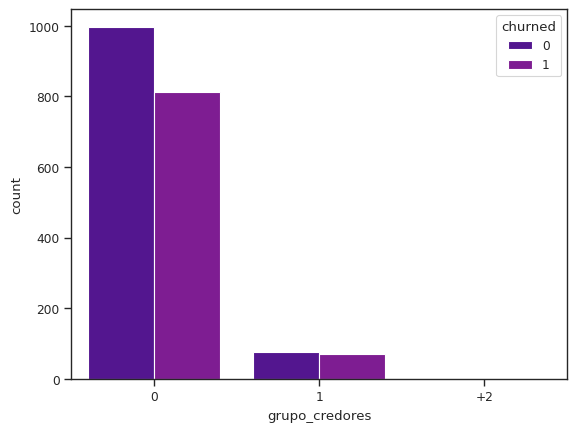

In [295]:
seaborn.countplot(data=leads,x='grupo_credores', hue='churned',order=['0','1','+2'])

Análise se existe alguma relação entre a variação da frequência de compra com churned

In [296]:
MIN_DIAS_COM_PEDIDO = 2 #pra poder analisar variação
LIMIAR_ESTAVEL = 0.2 # |variacao_idx| abaixo disso = 'Estável'
N_PERIODOS_TRAJETORIA = 6 #nº de fatias de tempo no gráfico de trajetória

pedidos['data'] = pandas.to_datetime(pedidos['data_entrega'])
DATA_INI, DATA_FIM = pedidos['data'].min(), pedidos['data'].max()
N_DIAS = (DATA_FIM - DATA_INI).days + 1
CORTE = DATA_INI + pandas.Timedelta(days=N_DIAS // 2) #divide o período ao meio

dias_cliente = (
    pedidos[['id_cliente', 'data']]
    .drop_duplicates()
    .sort_values(['id_cliente', 'data'])
    .reset_index(drop=True)
)
dias_cliente['janela'] = np.where(dias_cliente['data'] < CORTE, 'inicio', 'fim')

print(f'período: {DATA_INI.date()} -> {DATA_FIM.date()} ({N_DIAS} dias) | corte: {CORTE.date()}')

freq_janela = (
    pandas.crosstab(dias_cliente['id_cliente'], dias_cliente['janela'])
    .reindex(columns=['inicio', 'fim'], fill_value=0)
    .rename(columns={'inicio': 'dias_inicio', 'fim': 'dias_fim'})
    .rename_axis(columns=None)
)
freq_janela['n_dias'] = freq_janela['dias_inicio'] + freq_janela['dias_fim']
freq_janela['variacao_abs'] = freq_janela['dias_fim'] - freq_janela['dias_inicio']
freq_janela['variacao_idx'] = freq_janela['variacao_abs'] / freq_janela['n_dias']

linhas = []
for id_cliente, datas in dias_cliente.groupby('id_cliente')['data']:
    intervalos = datas.diff().dropna().dt.days.to_numpy()
    k = len(intervalos)
    if k >= 2:
        m = k // 2 
        ini, fim = intervalos[:m].mean(), intervalos[-m:].mean()
    else:
        ini = fim = np.nan
    linhas.append({'id_cliente': id_cliente, 'intervalo_inicial': ini, 'intervalo_final': fim})

intervalos_cliente = pandas.DataFrame(linhas)
intervalos_cliente['aceleracao_dias'] = intervalos_cliente['intervalo_inicial'] - intervalos_cliente['intervalo_final']

#linha por cliente (apenas quem tem pedidos)
var_freq = (
    base_clientes.loc[base_clientes['tem_pedido'] == 1, ['id_cliente', 'churned']]
    .merge(freq_janela.reset_index(), on='id_cliente', how='left', validate='one_to_one')
    .merge(intervalos_cliente, on='id_cliente', how='left', validate='one_to_one')
)

print(f"clientes com pedido: {len(var_freq)} | removidos por terem < {MIN_DIAS_COM_PEDIDO} dias com pedido: {(var_freq['n_dias'] < MIN_DIAS_COM_PEDIDO).sum()}")
var_freq = var_freq[var_freq['n_dias'] >= MIN_DIAS_COM_PEDIDO].copy()

#Classificação da trajetória
ORDEM_TRAJETORIA = ['Parou de comprar', 'Comprou menos', 'Estável', 'Comprou mais', 'Começou a comprar']

var_freq['trajetoria'] = np.select(
    [
        var_freq['dias_fim'] == 0, #só comprou na 1ª metade
        var_freq['dias_inicio'] == 0, #só comprou na 2ª metade
        var_freq['variacao_idx'] <= -LIMIAR_ESTAVEL,
        var_freq['variacao_idx'] >= LIMIAR_ESTAVEL,
    ],
    ['Parou de comprar', 'Começou a comprar', 'Comprou menos', 'Comprou mais'],
    default='Estável',
)
var_freq['trajetoria'] = pandas.Categorical(var_freq['trajetoria'], categories=ORDEM_TRAJETORIA, ordered=True)

print(f"clientes analisados: {len(var_freq)} | com variação de intervalo calculável (≥ 3 dias com pedido): {var_freq['aceleracao_dias'].notna().sum()}")
var_freq.head()

período: 2024-09-01 -> 2024-12-01 (92 dias) | corte: 2024-10-17
clientes com pedido: 1000 | removidos por terem < 2 dias com pedido: 306
clientes analisados: 694 | com variação de intervalo calculável (≥ 3 dias com pedido): 521


,id_cliente,churned,dias_inicio,dias_fim,n_dias,variacao_abs,variacao_idx,intervalo_inicial,intervalo_final,aceleracao_dias,trajetoria
0,4524631448006,0,4,4,8,0,0.000000,9.333333,10.333333,-1.0,Estável
1,4938228934646,0,2,0,2,-2,-1.000000,NaN,NaN,NaN,Parou de comprar
2,1464018550681,0,7,5,12,-2,-0.166667,7.200000,8.600000,-1.4,Estável
3,2318101682269,0,6,3,9,-3,-0.333333,7.000000,14.000000,-7.0,Comprou menos
4,7070800028323,0,2,2,4,0,0.000000,33.000000,1.000000,32.0,Estável


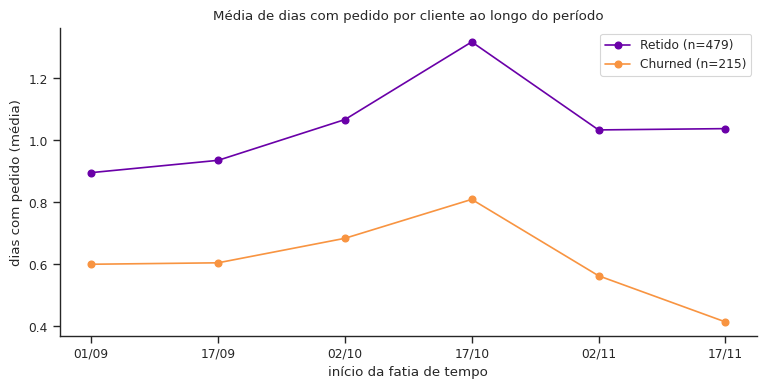

In [61]:
#Como churn se desenha ao longo do tempo
PALETA_CHURN = {0: '#6a00a8', 1: '#f89441'}
ROTULO_CHURN = {0: 'Retido', 1: 'Churned'}

offset = (dias_cliente['data'] - DATA_INI).dt.days
dias_cliente['periodo'] = np.minimum(offset * N_PERIODOS_TRAJETORIA // N_DIAS, N_PERIODOS_TRAJETORIA - 1)

por_periodo = (
    pandas.crosstab(dias_cliente['id_cliente'], dias_cliente['periodo'])
    .reindex(columns=range(N_PERIODOS_TRAJETORIA), fill_value=0)
    .reindex(var_freq['id_cliente'], fill_value=0)
)
por_periodo['churned'] = var_freq.set_index('id_cliente')['churned']

trajetoria_media = por_periodo.groupby('churned').mean().T
inicio_periodo = [DATA_INI + pandas.Timedelta(days=int(np.ceil(i * N_DIAS / N_PERIODOS_TRAJETORIA))) for i in range(N_PERIODOS_TRAJETORIA)]
rotulos = [d.strftime('%d/%m') for d in inicio_periodo]

fig, ax = plot.subplots(figsize=(9, 4))
for churned in (0, 1):
    ax.plot(rotulos, trajetoria_media[churned], marker='o', color=PALETA_CHURN[churned],
            label=f'{ROTULO_CHURN[churned]} (n={(var_freq.churned == churned).sum()})')
ax.set_title('Média de dias com pedido por cliente ao longo do período')
ax.set_xlabel('início da fatia de tempo')
ax.set_ylabel('dias com pedido (média)')
ax.legend()
seaborn.despine()
plot.show()

 Se churned costuma desacelerar antes de sair, a curva dele cai ao longo do tempo enquanto a dos retidos fica estável.

Cada cliente é classificado como Parou de comprar, Comprou menos, Estável, Comprou mais ou Começou a comprar conforme a mudança de frequência entre as duas metades do período. A linha tracejada é a taxa de churn média dos clientes analisados.

,clientes,churn,taxa_churn
trajetoria,,,
Parou de comprar,54,30,55.6
Comprou menos,138,44,31.9
Estável,255,70,27.5
Comprou mais,161,34,21.1
Começou a comprar,86,37,43.0


qui-quadrado: p = 5.017e-06 | V de Cramér = 0.208 | menor frequência esperada = 16.7


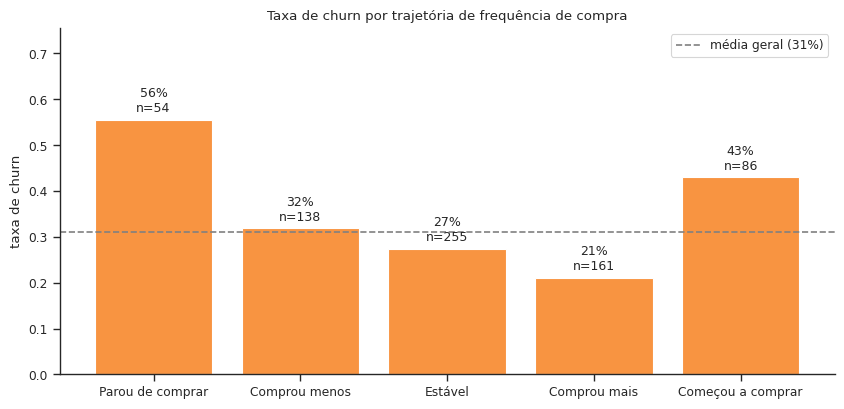

In [298]:
def taxa_por_categoria(df, coluna, ordem=None):
    tabela = df.groupby(coluna, observed=True)['churned'].agg(clientes='count', churn='sum', taxa_churn='mean')
    return tabela.reindex(ordem).dropna(subset=['clientes']) if ordem is not None else tabela


def chi2_categorico(df, coluna):
    ct = pandas.crosstab(df[coluna], df['churned'])
    ct = ct.loc[ct.sum(axis=1) > 0] # categorias sem nenhum cliente zerariam a frequência esperada
    chi2, p, _, esperado = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return p, cramer_v, esperado.min()


def barras_taxa_churn(tabela, ax, titulo, referencia=None, rotacao=0):
    # barras com a taxa de churn por categoria e o n de cada uma em cima
    tabela = tabela.copy()
    tabela.index = tabela.index.astype(str)
    ax.bar(tabela.index, tabela['taxa_churn'], color=PALETA_CHURN[1])
    for i, (n, taxa) in enumerate(zip(tabela['clientes'], tabela['taxa_churn'])):
        ax.text(i, taxa + 0.01, f'{taxa:.0%}\nn={int(n)}', ha='center', va='bottom', fontsize=9)
    if referencia is not None:
        ax.axhline(referencia, color='gray', linestyle='--', label=f'média geral ({referencia:.0%})')
        ax.legend(loc='upper right')
    ax.set_ylim(0, min(1.15, tabela['taxa_churn'].max() + 0.2))
    ax.set_title(titulo)
    ax.set_ylabel('taxa de churn')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=rotacao)


taxa_geral = var_freq['churned'].mean()
tab_traj = taxa_por_categoria(var_freq, 'trajetoria', ORDEM_TRAJETORIA)
display(tab_traj.assign(taxa_churn=(tab_traj['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(var_freq, 'trajetoria')
print(f'qui-quadrado: p = {p:.4g} | V de Cramér = {v:.3f} | menor frequência esperada = {esp_min:.1f}'
      + ('  (atenção: < 5, interprete com cautela)' if esp_min < 5 else ''))

fig, ax = plot.subplots(figsize=(10, 4.5))
barras_taxa_churn(tab_traj, ax, 'Taxa de churn por trajetória de frequência de compra', referencia=taxa_geral)
seaborn.despine()
plot.show()

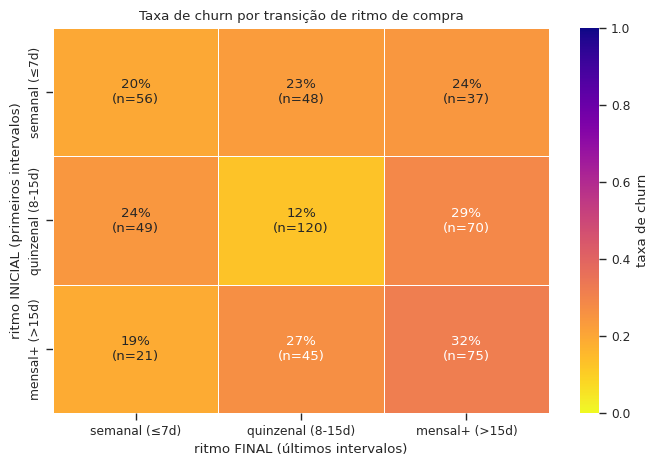

,clientes,churn,taxa_churn
mudanca_de_ritmo,,,
Acelerou (mudou p/ faixa mais rápida),115,28,24.3
Desacelerou (mudou p/ faixa mais lenta),155,40,25.8
Manteve a faixa,251,50,19.9


In [299]:
# a transição em si da frequência
FAIXAS_INTERVALO = [0, 7, 15, np.inf]
ROTULOS_INTERVALO = ['semanal (≤7d)', 'quinzenal (8-15d)', 'mensal+ (>15d)']

recorrentes = var_freq.dropna(subset=['intervalo_inicial', 'intervalo_final']).copy()
recorrentes['ritmo_inicial'] = pandas.cut(recorrentes['intervalo_inicial'], FAIXAS_INTERVALO, labels=ROTULOS_INTERVALO)
recorrentes['ritmo_final'] = pandas.cut(recorrentes['intervalo_final'], FAIXAS_INTERVALO, labels=ROTULOS_INTERVALO)

agrupado = recorrentes.groupby(['ritmo_inicial', 'ritmo_final'], observed=False)['churned'].agg(['mean', 'count'])
taxa_mx = agrupado['mean'].unstack()
n_mx = agrupado['count'].unstack().fillna(0).astype(int)

anotacoes = np.empty(taxa_mx.shape, dtype=object)
for i in range(taxa_mx.shape[0]):
    for j in range(taxa_mx.shape[1]):
        anotacoes[i, j] = '' if n_mx.iat[i, j] == 0 else f'{taxa_mx.iat[i, j]:.0%}\n(n={n_mx.iat[i, j]})'

fig, ax = plot.subplots(figsize=(8, 5))
seaborn.heatmap(taxa_mx, annot=anotacoes, fmt='', cmap='plasma_r', vmin=0, vmax=1, mask=taxa_mx.isna(),
                linewidths=0.5, cbar_kws={'label': 'taxa de churn'}, ax=ax)
ax.set_title('Taxa de churn por transição de ritmo de compra')
ax.set_xlabel('ritmo FINAL (últimos intervalos)')
ax.set_ylabel('ritmo INICIAL (primeiros intervalos)')
plot.show()

# resumo: quem desacelerou x manteve x acelerou de faixa
nivel = {r: i for i, r in enumerate(ROTULOS_INTERVALO)}
dif = recorrentes['ritmo_final'].map(nivel).astype(int) - recorrentes['ritmo_inicial'].map(nivel).astype(int)
recorrentes['mudanca_de_ritmo'] = np.select([dif > 0, dif < 0], ['Desacelerou (mudou p/ faixa mais lenta)', 'Acelerou (mudou p/ faixa mais rápida)'], 'Manteve a faixa')
display(taxa_por_categoria(recorrentes, 'mudanca_de_ritmo').assign(taxa_churn=lambda d: (d['taxa_churn'] * 100).round(1)))

taxa mudou mt pouco, aparentemente não tem essa mudança na frequência gradual

correlação direto e avaliar frequência positiva (se comprou mais) e negativa (se comprou menos)

Convenção: variação positiva = comprou mais, negativa = comprou menos. Para a correlação com churned (1 = churned):

Spearman / ponto-bisserial negativo → quanto mais o cliente aumentou as compras, menos ele dá churn (sinal esperado).
Mann-Whitney compara a distribuição da variação entre churned e retidos (não assume normalidade, e a variação é discreta e assimétrica).
Por fim, o sinal é separado em 3 grupos (negativa / zero / positiva) e comparado por qui-quadrado e odds ratio.

In [64]:
def testes_variacao(df, coluna):
    d = df[[coluna, 'churned']].dropna()
    ret, chu = d.loc[d.churned == 0, coluna], d.loc[d.churned == 1, coluna]
    rho, p_rho = stats.spearmanr(d[coluna], d['churned'])
    r_pb, p_pb = stats.pointbiserialr(d['churned'], d[coluna])
    _, p_mw = stats.mannwhitneyu(chu, ret)
    return {'variável': coluna, 'n': len(d),
            'mediana (retido)': ret.median(), 'mediana (churned)': chu.median(),
            'Spearman': rho, 'p (Spearman)': p_rho,
            'ponto-bisserial': r_pb, 'p (Mann-Whitney)': p_mw}


resumo_corr = pandas.DataFrame([
    testes_variacao(var_freq, 'variacao_abs'),
    testes_variacao(var_freq, 'variacao_idx'),
    testes_variacao(var_freq, 'aceleracao_dias'),
]).set_index('variável')
display(resumo_corr.round(4))

,n,mediana (retido),mediana (churned),Spearman,p (Spearman),ponto-bisserial,p (Mann-Whitney)
variável,,,,,,,
variacao_abs,694,0.0000,0.0,-0.0976,0.0101,-0.1174,0.0102
variacao_idx,694,0.0000,0.0,-0.0776,0.0410,-0.0741,0.0411
aceleracao_dias,521,-0.5556,-2.5,-0.0584,0.1830,-0.0871,0.1829


,clientes,churn,taxa_churn
sinal_variacao,,,
Negativa (comprou menos),233,78,33.5
Zero (sem mudança),168,62,36.9
Positiva (comprou mais),293,75,25.6


qui-quadrado (3 grupos): p = 0.02463 | V de Cramér = 0.103
odds ratio (negativa vs positiva) = 1.46 | p (Fisher) = 0.05342
  -> OR > 1: quem comprou menos tem mais chance de churn do que quem comprou mais


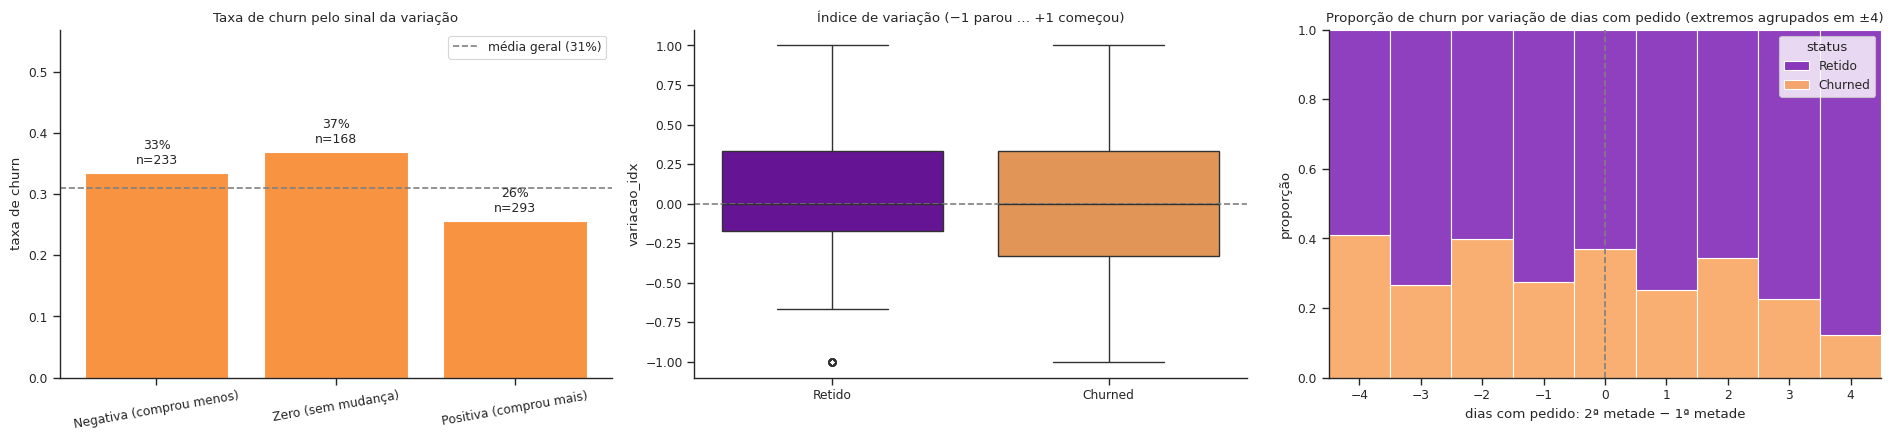

In [301]:
#Sinal da variação: negativa / zero / positiva
ORDEM_SINAL = ['Negativa (comprou menos)', 'Zero (sem mudança)', 'Positiva (comprou mais)']
var_freq['sinal_variacao'] = pandas.Categorical(
    np.select([var_freq['variacao_abs'] < 0, var_freq['variacao_abs'] > 0],
              [ORDEM_SINAL[0], ORDEM_SINAL[2]], default=ORDEM_SINAL[1]),
    categories=ORDEM_SINAL, ordered=True)

tab_sinal = taxa_por_categoria(var_freq, 'sinal_variacao', ORDEM_SINAL)
display(tab_sinal.assign(taxa_churn=(tab_sinal['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(var_freq, 'sinal_variacao')
print(f'qui-quadrado (3 grupos): p = {p:.4g} | V de Cramér = {v:.3f}')

neg = var_freq[var_freq['sinal_variacao'] == ORDEM_SINAL[0]]['churned']
pos = var_freq[var_freq['sinal_variacao'] == ORDEM_SINAL[2]]['churned']
odds_ratio, p_fisher = stats.fisher_exact([[neg.sum(), (neg == 0).sum()], [pos.sum(), (pos == 0).sum()]])
print(f'odds ratio (negativa vs positiva) = {odds_ratio:.2f} | p (Fisher) = {p_fisher:.4g}')
print('  -> OR > 1: quem comprou menos tem mais chance de churn do que quem comprou mais')

fig, axes = plot.subplots(1, 3, figsize=(19, 4.5))

barras_taxa_churn(tab_sinal, axes[0], 'Taxa de churn pelo sinal da variação', referencia=taxa_geral, rotacao=10)

seaborn.boxplot(data=var_freq, x='churned', y='variacao_idx', hue='churned', palette=PALETA_CHURN, legend=False, ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_xticks([0, 1], ['Retido', 'Churned'])
axes[1].set_title('Índice de variação (−1 parou … +1 começou)')
axes[1].set_xlabel('')

var_freq['variacao_abs_corte'] = var_freq['variacao_abs'].clip(-4, 4) # extremos agrupados em ±4
var_freq['status'] = var_freq['churned'].map(ROTULO_CHURN)
seaborn.histplot(data=var_freq, x='variacao_abs_corte', hue='status', multiple='fill', discrete=True,
                 palette={ROTULO_CHURN[k]: c for k, c in PALETA_CHURN.items()}, hue_order=['Retido', 'Churned'], ax=axes[2])
axes[2].axvline(0, color='gray', linestyle='--')
axes[2].set_title('Proporção de churn por variação de dias com pedido (extremos agrupados em ±4)')
axes[2].set_xlabel('dias com pedido: 2ª metade − 1ª metade')
axes[2].set_ylabel('proporção')
seaborn.despine()
plot.tight_layout()
plot.show()

Ou seja, quem comprou menos tem de fato mais chance de churn do que quem comprou mais.

recencia_dias já tem forte relação com o churn (Spearman ≈ +0,44 acima). Como quem parou de comprar também tem recência alta, boa parte do sinal "negativo" pode ser a própria recência. Vale checar a variação controlando por recência antes de usá-la como feature (ex.: olhar só clientes com recência baixa).

,n,taxa_churn,Spearman,p-valor
faixa_recencia,,,,
0-15d,386,0.1736,0.1237,0.0150
16-30d,158,0.4051,0.0816,0.3084
31-60d,134,0.5448,0.0647,0.4574
61d+,16,0.6875,NaN,NaN


Spearman bruto (variação x churn):           -0.078
Spearman parcial (controlando a recência):   +0.078 | p = 0.03986
  -> se o parcial for bem menor (em módulo) que o bruto, a variação era em boa parte recência


clientes  taxa_churn
faixa_recencia sinal_variacao                                
0-15d          Negativa (comprou menos)        89       0.135
               Zero (sem mudança)              82       0.159
               Positiva (comprou mais)        215       0.195
16-30d         Negativa (comprou menos)        52       0.346
               Zero (sem mudança)              45       0.467
               Positiva (comprou mais)         61       0.410
31-60d         Negativa (comprou menos)        76       0.487
               Zero (sem mudança)              41       0.683
               Positiva (comprou mais)         17       0.471
61d+           Negativa (comprou menos)        16       0.688

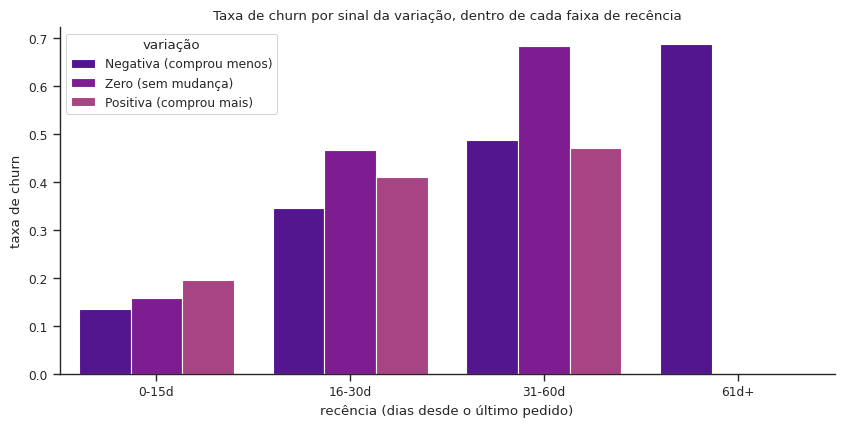

In [302]:
# Variação x churn CONTROLANDO por recência
var_rec = var_freq.merge(base_clientes[['id_cliente', 'recencia_dias']], on='id_cliente', how='left', validate='one_to_one')

FAIXAS_RECENCIA = [-1, 15, 30, 60, np.inf]
ROTULOS_RECENCIA = ['0-15d', '16-30d', '31-60d', '61d+']
var_rec['faixa_recencia'] = pandas.cut(var_rec['recencia_dias'], FAIXAS_RECENCIA, labels=ROTULOS_RECENCIA)

#se o sinal era só recência, o Spearman fica perto de 0 em cada faixa
linhas = []
for faixa, d in var_rec.groupby('faixa_recencia', observed=True):
    if len(d) < 30 or d['churned'].nunique() < 2 or d['variacao_idx'].nunique() < 2:
        linhas.append({'faixa_recencia': faixa, 'n': len(d), 'taxa_churn': d['churned'].mean(), 'Spearman': np.nan, 'p-valor': np.nan})
        continue
    rho, p = stats.spearmanr(d['variacao_idx'], d['churned'])
    linhas.append({'faixa_recencia': faixa, 'n': len(d), 'taxa_churn': d['churned'].mean(), 'Spearman': rho, 'p-valor': p})
display(pandas.DataFrame(linhas).set_index('faixa_recencia').round(4))

#correlação variação x churn removendo o efeito linear da recência (nos ranks)
ranks = var_rec[['variacao_idx', 'churned', 'recencia_dias']].rank()
def residuos(y, x):
    return y - np.polyval(np.polyfit(x, y, 1), x)

rho_bruto = stats.spearmanr(var_rec['variacao_idx'], var_rec['churned'])[0]
rho_parcial = np.corrcoef(residuos(ranks['variacao_idx'], ranks['recencia_dias']),
                          residuos(ranks['churned'], ranks['recencia_dias']))[0, 1]
n = len(ranks)
t = rho_parcial * np.sqrt((n - 3) / (1 - rho_parcial ** 2))
p_parcial = 2 * stats.t.sf(abs(t), n - 3)
print(f'Spearman bruto (variação x churn):           {rho_bruto:+.3f}')
print(f'Spearman parcial (controlando a recência):   {rho_parcial:+.3f} | p = {p_parcial:.4g}')
print('  -> se o parcial for bem menor (em módulo) que o bruto, a variação era em boa parte recência')

#Taxa de churn por sinal da variação, dentro de cada faixa de recência
display(var_rec.groupby(['faixa_recencia', 'sinal_variacao'], observed=True)['churned']
        .agg(clientes='count', taxa_churn='mean').round(3))

fig, ax = plot.subplots(figsize=(10, 4.5))
seaborn.barplot(data=var_rec, x='faixa_recencia', y='churned', hue='sinal_variacao',
                order=ROTULOS_RECENCIA, errorbar=None, ax=ax)
ax.set_title('Taxa de churn por sinal da variação, dentro de cada faixa de recência')
ax.set_xlabel('recência (dias desde o último pedido)')
ax.set_ylabel('taxa de churn')
ax.legend(title='variação')
seaborn.despine()
plot.show()

análise da coluna 'produto' e 'valor' discretizando o intervalos que existem em cada uma para fazer uma análise categórica de ambas individualmente com o fato de terem dado churned ou não

In [67]:
def faixas_por_cliente(coluna):
    # ordem natural das faixas, do menor para o maior intervalo (usa o helper sort_by_range definido acima)
    ordem = sort_by_range(pedidos[coluna].dropna().unique())
    tipo = pandas.CategoricalDtype(ordem, ordered=True)

    ped = pedidos[['id_cliente', coluna]].dropna().copy()
    ped[coluna] = ped[coluna].astype(tipo)

    contagem = pandas.crosstab(ped['id_cliente'], ped[coluna]).reindex(columns=ordem)
    # moda com empate -> faixa maior: inverte as colunas para o idxmax pegar a última em caso de empate
    moda = contagem.iloc[:, ::-1].idxmax(axis=1)
    maxima = ped.groupby('id_cliente', observed=True)[coluna].max()

    return ordem, tipo, contagem, moda.astype(tipo), maxima.astype(tipo)


def analise_faixa_cliente(coluna, rotulo):
    ordem, tipo, contagem, moda, maxima = faixas_por_cliente(coluna)

    clientes = base_clientes.loc[base_clientes['tem_pedido'] == 1, ['id_cliente', 'churned']].set_index('id_cliente')
    clientes = clientes.join(moda.rename('faixa_moda')).join(maxima.rename('faixa_maxima')).dropna()
    referencia = clientes['churned'].mean()

    fig, axes = plot.subplots(1, 2, figsize=(16, 4.5))
    for ax, col, titulo in [(axes[0], 'faixa_moda', f'faixa de {rotulo.lower()} mais frequente do cliente'),
                            (axes[1], 'faixa_maxima', f'maior faixa de {rotulo.lower()} já atingida pelo cliente')]:
        clientes[col] = clientes[col].astype(tipo)
        tabela = taxa_por_categoria(clientes, col, ordem)
        p, v, esp_min = chi2_categorico(clientes, col)
        aviso = '  (atenção: frequência esperada < 5 em alguma faixa)' if esp_min < 5 else ''
        print(f'[{rotulo}] {titulo}: p = {p:.4g} | V de Cramér = {v:.3f}{aviso}')
        display(tabela.assign(taxa_churn=(tabela['taxa_churn'] * 100).round(1)))
        barras_taxa_churn(tabela, ax, f'Churn por {titulo}', referencia=referencia)
    seaborn.despine()
    plot.tight_layout()
    plot.show()

    # "já fez pelo menos um pedido nessa faixa?"
    linhas = []
    base = clientes.join(contagem)
    for faixa in ordem:
        fez = base[faixa] > 0
        linhas.append({'faixa': faixa,
                       'clientes que já pediram': int(fez.sum()),
                       'churn (já pediu)': base.loc[fez, 'churned'].mean(),
                       'churn (nunca pediu)': base.loc[~fez, 'churned'].mean()})
    display(pandas.DataFrame(linhas).set_index('faixa').round(3))

[Valor] faixa de valor mais frequente do cliente: p = 0.8062 | V de Cramér = 0.031


,clientes,churn,taxa_churn
faixa_moda,,,
"(0, 500]",780,348,44.6
"(500, 1000]",151,66,43.7
"(1000, 2000]",49,20,40.8
"(2000, 10000000]",20,7,35.0


[Valor] maior faixa de valor já atingida pelo cliente: p = 4.396e-07 | V de Cramér = 0.180


,clientes,churn,taxa_churn
faixa_maxima,,,
"(0, 500]",644,325,50.5
"(500, 1000]",223,80,35.9
"(1000, 2000]",92,25,27.2
"(2000, 10000000]",41,11,26.8


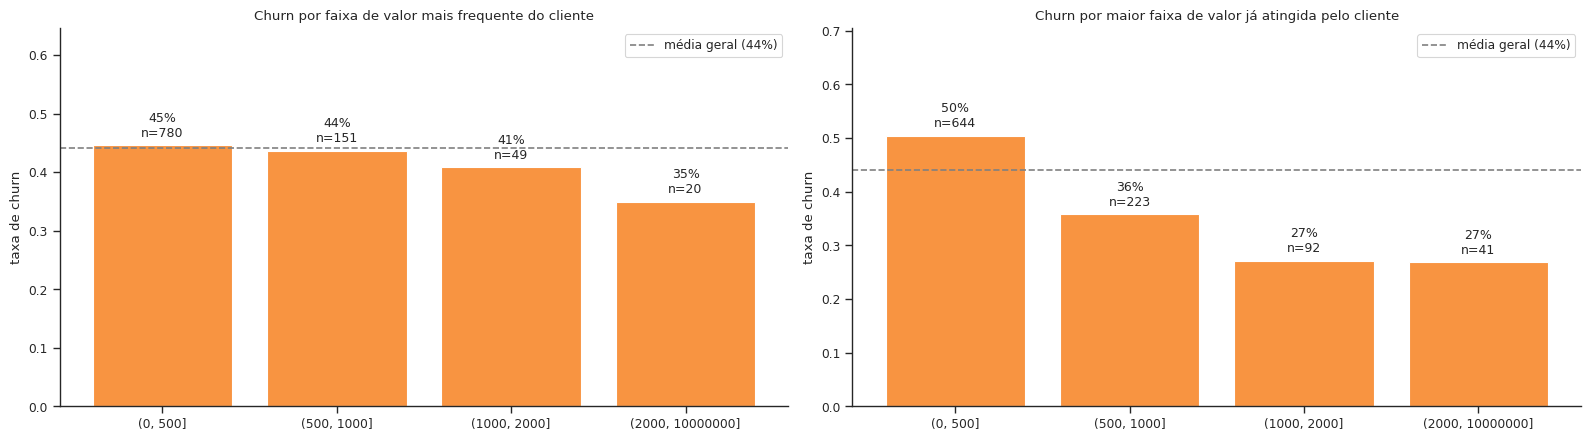

,clientes que já pediram,churn (já pediu),churn (nunca pediu)
faixa,,,
"(0, 500]",889,0.431,0.523
"(500, 1000]",311,0.318,0.496
"(1000, 2000]",121,0.264,0.465
"(2000, 10000000]",41,0.268,0.448


In [304]:
analise_faixa_cliente('valor', 'Valor')

[Produtos] faixa de produtos mais frequente do cliente: p = 0.7425 | V de Cramér = 0.024


,clientes,churn,taxa_churn
faixa_moda,,,
"(0, 5]",906,403,44.5
"(5, 10]",75,30,40.0
"(10, 10000000]",19,8,42.1


[Produtos] maior faixa de produtos já atingida pelo cliente: p = 4.134e-09 | V de Cramér = 0.196


,clientes,churn,taxa_churn
faixa_maxima,,,
"(0, 5]",787,387,49.2
"(5, 10]",160,41,25.6
"(10, 10000000]",53,13,24.5


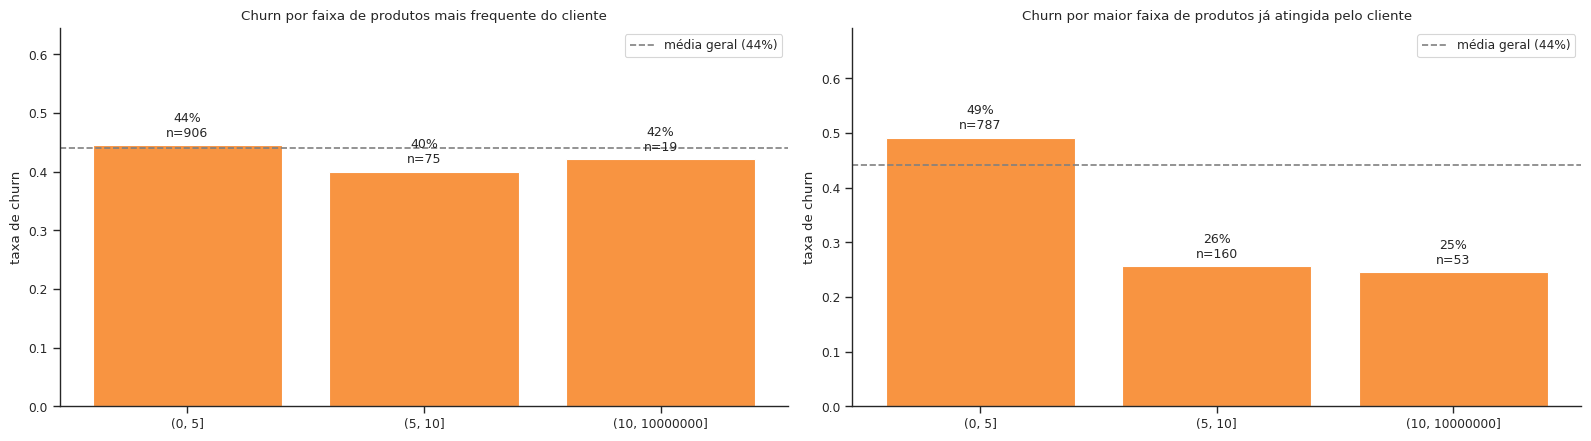

,clientes que já pediram,churn (já pediu),churn (nunca pediu)
faixa,,,
"(0, 5]",963,0.434,0.622
"(5, 10]",206,0.248,0.491
"(10, 10000000]",53,0.245,0.452


In [305]:
analise_faixa_cliente('produtos', 'Produtos')

Contagem de pedido no total por cliente vs churned

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
Churned,904.0,1.19,2.57,0.0,0.0,0.0,1.0,46.0
Retido,1096.0,3.07,4.88,0.0,0.0,1.0,5.0,56.0


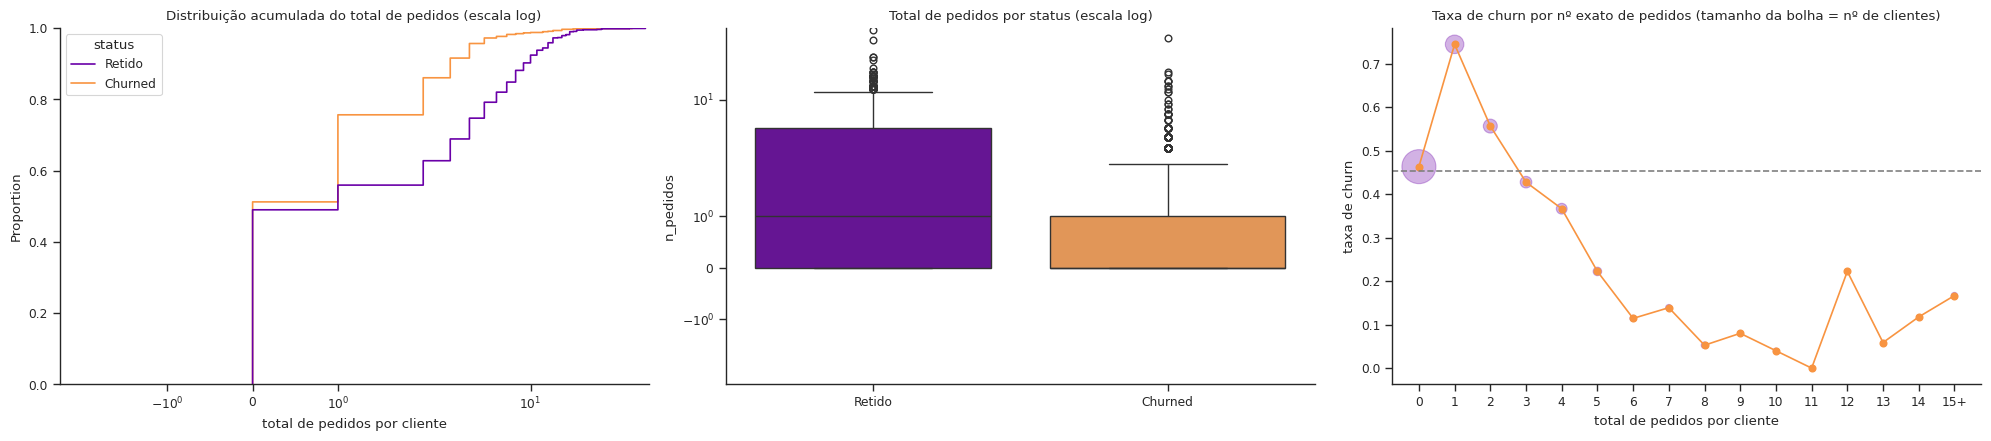

In [306]:
total_pedidos = base_clientes[['id_cliente', 'churned', 'n_pedidos']].copy()
total_pedidos['n_pedidos'] = total_pedidos['n_pedidos'].fillna(0).astype(int)      # sem pedido = 0
total_pedidos['status'] = total_pedidos['churned'].map(ROTULO_CHURN)

display(total_pedidos.groupby('status')['n_pedidos'].describe().round(2))

fig, axes = plot.subplots(1, 3, figsize=(20, 4.5))
cores = {ROTULO_CHURN[k]: c for k, c in PALETA_CHURN.items()}

seaborn.ecdfplot(data=total_pedidos, x='n_pedidos', hue='status', palette=cores, hue_order=['Retido', 'Churned'], ax=axes[0])
axes[0].set_xscale('symlog')
axes[0].set_title('Distribuição acumulada do total de pedidos (escala log)')
axes[0].set_xlabel('total de pedidos por cliente')

seaborn.boxplot(data=total_pedidos, x='status', y='n_pedidos', hue='status', palette=cores, order=['Retido', 'Churned'], legend=False, ax=axes[1])
axes[1].set_yscale('symlog')
axes[1].set_title('Total de pedidos por status (escala log)')
axes[1].set_xlabel('')

# taxa de churn para cada contagem exata (agrupando a cauda em TETO+)
TETO = 15
exata = total_pedidos.assign(n_exato=total_pedidos['n_pedidos'].clip(upper=TETO))
curva = exata.groupby('n_exato')['churned'].agg(clientes='count', taxa='mean')
axes[2].plot(curva.index, curva['taxa'], marker='o', color=PALETA_CHURN[1])
axes[2].scatter(curva.index, curva['taxa'], s=curva['clientes'] / curva['clientes'].max() * 600, alpha=0.3, color=PALETA_CHURN[0])
axes[2].axhline(total_pedidos['churned'].mean(), color='gray', linestyle='--')
axes[2].set_xticks(curva.index, [str(i) if i < TETO else f'{TETO}+' for i in curva.index])
axes[2].set_title('Taxa de churn por nº exato de pedidos (tamanho da bolha = nº de clientes)')
axes[2].set_xlabel('total de pedidos por cliente')
axes[2].set_ylabel('taxa de churn')
seaborn.despine()
plot.tight_layout()
plot.show()

,clientes,churn,taxa_churn
faixa_pedidos,,,
0,1000,463,46.3
1,297,221,74.4
2,169,94,55.6
3-4,218,87,39.9
5-7,134,23,17.2
8-12,112,7,6.2
13+,70,9,12.9


qui-quadrado: p = 7.862e-52 | V de Cramér = 0.356 | menor frequência esperada = 31.6


,n,Spearman,p (Spearman),ponto-bisserial,p (Mann-Whitney)
base,,,,,
todos os leads (inclui 0 pedidos),2000,-0.1514,0.0,-0.2272,0.0
só clientes com pedido,1000,-0.4983,0.0,-0.3627,0.0


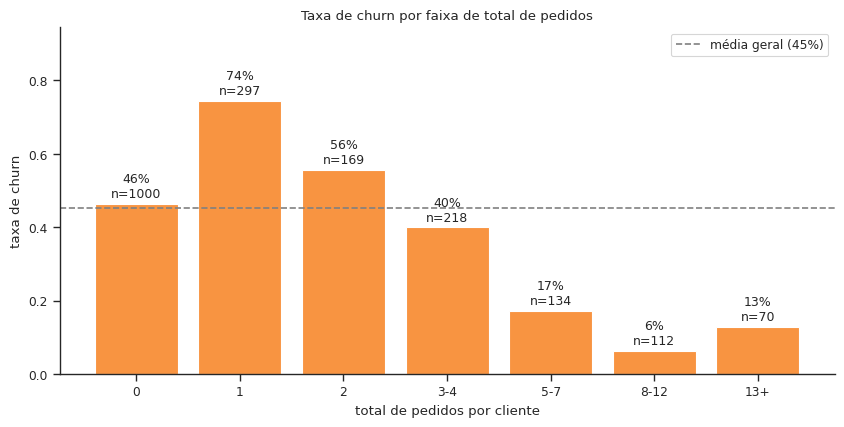

In [71]:
#faixa de total de pedidos
BINS_PEDIDOS = [-1, 0, 1, 2, 4, 7, 12, np.inf]
ROTULOS_PEDIDOS = ['0', '1', '2', '3-4', '5-7', '8-12', '13+']

total_pedidos['faixa_pedidos'] = pandas.cut(total_pedidos['n_pedidos'], BINS_PEDIDOS, labels=ROTULOS_PEDIDOS)
tab_ped = taxa_por_categoria(total_pedidos, 'faixa_pedidos', ROTULOS_PEDIDOS)
display(tab_ped.assign(taxa_churn=(tab_ped['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(total_pedidos, 'faixa_pedidos')
print(f'qui-quadrado: p = {p:.4g} | V de Cramér = {v:.3f} | menor frequência esperada = {esp_min:.1f}')

# correlações: todos os leads x só quem pediu
linhas = []
for nome, base in [('todos os leads (inclui 0 pedidos)', total_pedidos), ('só clientes com pedido', total_pedidos[total_pedidos['n_pedidos'] > 0])]:
    rho, p_rho = stats.spearmanr(base['n_pedidos'], base['churned'])
    r_pb, p_pb = stats.pointbiserialr(base['churned'], base['n_pedidos'])
    _, p_mw = stats.mannwhitneyu(base.loc[base.churned == 1, 'n_pedidos'], base.loc[base.churned == 0, 'n_pedidos'])
    linhas.append({'base': nome, 'n': len(base), 'Spearman': rho, 'p (Spearman)': p_rho,
                   'ponto-bisserial': r_pb, 'p (Mann-Whitney)': p_mw})
display(pandas.DataFrame(linhas).set_index('base').round(4))

fig, ax = plot.subplots(figsize=(10, 4.5))
barras_taxa_churn(tab_ped, ax, 'Taxa de churn por faixa de total de pedidos', referencia=total_pedidos['churned'].mean())
ax.set_xlabel('total de pedidos por cliente')
seaborn.despine()
plot.show()

Obs.: Não considerei que estamos num intervalo dos 90 dias, mas depois vou reavaliar isso.

---

verificando distribuições de variáveis de ifood/google maps em relação ao churn

In [72]:
# gambiarra
leads2 = leads.copy(deep=True)
leads2.ifood_faixa_preco = leads2.ifood_faixa_preco.dropna().sort_values().map(lambda str: str.replace('$', '\\$'))

<Axes: xlabel='churned', ylabel='ifood_faixa_preco'>

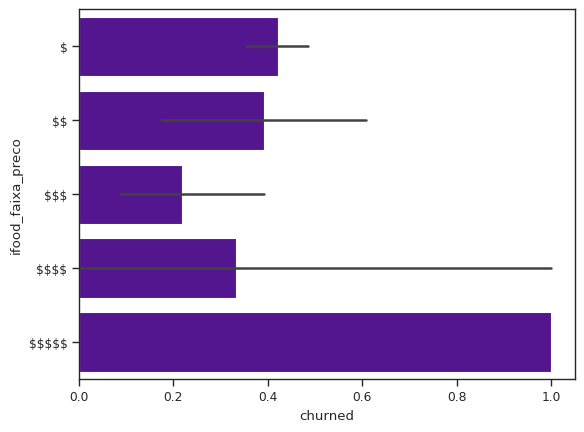

In [73]:
seaborn.barplot(data=leads2, x='churned', y='ifood_faixa_preco', order=sorted(leads2.ifood_faixa_preco.dropna().unique()))

In [74]:
leads.ifood_faixa_preco.value_counts(dropna=False)

ifood_faixa_preco
NaN      1757
$         192
$$$        23
$$         23
$$$$        3
$$$$$       2
Name: count, dtype: int64

é provável que essas porcentagens para as faixas de preço mais altas não representem o mundo real. agrupando:

caro_ifood
NaN      1757
False     215
True       28
Name: count, dtype: int64

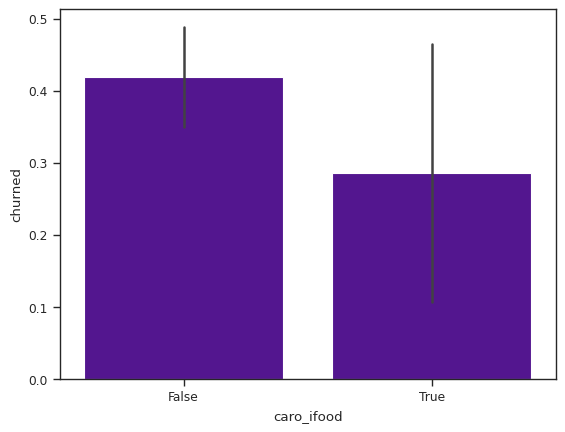

In [75]:
leads['caro_ifood'] = leads.ifood_faixa_preco.dropna().apply(lambda x: x in ('$$$', '$$$$', '$$$$$'))
seaborn.barplot(data=leads, x='caro_ifood', y='churned')

leads.caro_ifood.value_counts(dropna=False)

Porcentagem de clientes que dão churn por grupo de avaliação no google maps

<Axes: xlabel='churned', ylabel='google_maps_avaliacao'>

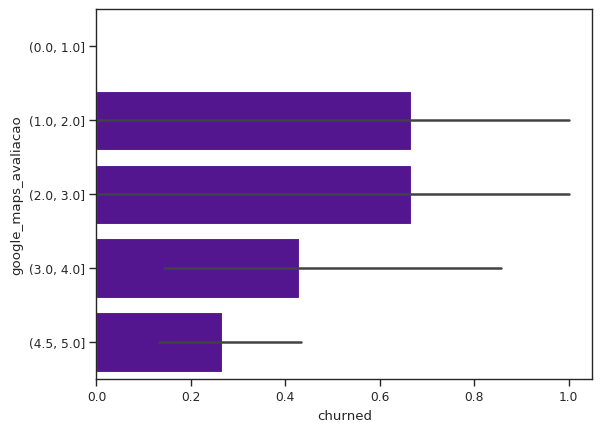

In [76]:
seaborn.barplot(data=leads, x='churned', y='google_maps_avaliacao', order=sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True))

Porcentagem de clientes que dão churn baseado na contagem de avaliações no google maps, agrupado pela avaliação do estabelecimento no google maps

<Axes: xlabel='churned', ylabel='google_maps_contagem_avaliacoes'>

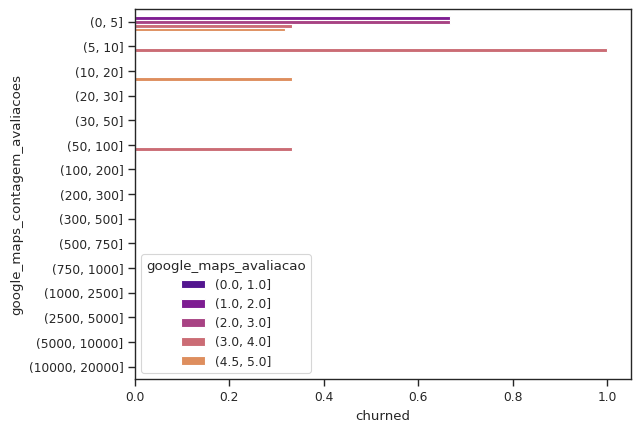

In [318]:
seaborn.barplot(
    data=leads,
    errorbar=None,
    x='churned',
    y='google_maps_contagem_avaliacoes',
    hue='google_maps_avaliacao',
    hue_order=sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True),
    order=sort_by_range(leads.google_maps_contagem_avaliacoes.dropna().unique())
)